# Jupyter Notebook in Teaching

Introduction to Jupyter - Finite elements for the heat equation - Physics-informed neural networks for the Navier-Stokes equations

**Contents**

- Setup
- Part 1: Introduction to Jupyter Notebook
  - 1.1 What is Jupyter?
  - 1.2 How it works
  - 1.3 Getting started
  - 1.4 Cells, modes and shortcuts
  - 1.5 Markdown and LaTeX
  - 1.6 Code cells and kernel state
  - 1.7 Rich output and magic commands
  - 1.8 Jupyter notebooks in teaching
  - 1.9 AI assistance for preparing notebooks
  - 1.10 Summary
- Part 2: Finite Elements for the 1D Heat Equation
  - 2.1 The model problem
  - 2.2 Spatial discretization: finite elements
  - 2.3 Time discretization: solving the ODE system
  - 2.4 Implementation
  - 2.5 Numerical results
  - 2.6 Error analysis
  - 2.7 Summary
- Part 3: Physics-Informed Neural Networks for the 2D Navier-Stokes Equations
  - 3.1 What is a PINN?
  - 3.2 The incompressible Navier-Stokes equations
  - 3.3 The PINN formulation for Navier-Stokes
  - 3.4 PyTorch essentials
  - 3.5 Implementing the PINN
  - 3.6 Training
  - 3.7 Results and visualization
  - 3.8 Summary
- References

## Setup

Run the cells from top to bottom with **Shift+Enter**. The first code cell imports the Python standard-library modules, **NumPy** (arrays), **SciPy** (sparse matrices and solvers) and **Matplotlib** (plots and animations), and prints the library versions; the second sets all plot defaults in one place. **PyTorch** is needed only in Part 3 and is imported there, so Parts 1 and 2 also run on a computer without it. A laptop CPU is enough; no GPU, internet connection or data files are needed.

In [165]:
# Python standard library
import math                           # mathematical constants and functions
import os                             # operating-system services (number of CPU cores)
import platform                       # Python / operating system information
import sys                            # the running Python interpreter
import time                           # wall-clock time
import warnings                       # control of warning messages
from pathlib import Path              # portable file paths (Windows, macOS, Linux)

# Third-party libraries
import numpy as np
import scipy
import scipy.sparse as sp             # sparse matrix formats (COO, CSR, CSC)
import scipy.sparse.linalg as spla    # sparse linear solvers
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation   # movies of time-dependent solutions (Part 2)
from matplotlib.patches import FancyBboxPatch    # rounded boxes in diagrams
from IPython.display import HTML                 # show HTML output, e.g. a movie player

print(f"Python     {platform.python_version()}")
print(f"NumPy      {np.__version__}")
print(f"SciPy      {scipy.__version__}")
print(f"Matplotlib {matplotlib.__version__}")

Python     3.10.14
NumPy      1.26.4
SciPy      1.13.0
Matplotlib 3.8.4


In [166]:
# show figures directly below the code cells (a "magic command", see Section 1.7)
%matplotlib inline

# All plot settings in one place (moderate resolution keeps the notebook file small).
plt.rcParams.update({
    "figure.dpi": 100,            # resolution of figures shown in the notebook
    "savefig.dpi": 110,           # resolution of figures saved with plt.savefig
    "font.size": 10,
    "axes.titlesize": 11,
    "image.cmap": "viridis",      # default colour map
})

# Part 1: Introduction to Jupyter Notebook

## 1.1 What is Jupyter?

- **IPython** ("interactive Python") was started in 2001 by Fernando Perez as a better interactive Python shell for scientists (Perez and Granger, 2007); in 2011 it gained a browser-based **notebook**.
- In **2014** the language-independent parts became **Project Jupyter**. The name comes from **Ju**lia, **Pyt**hon and **R**: the notebook is not tied to one language.

A **notebook** is a single document that combines **live code**, **narrative text** (Markdown), **equations** (LaTeX) and **results** (numbers, tables, figures). It records not only *what* was computed but also *how* (Kluyver et al., 2016).

> **Key idea.** This is Knuth's **literate programming** (Knuth, 1984) in practice: code embedded in an explanation written for humans. A good notebook reads like a lecture note that you can execute.

| Tool | What it is |
|---|---|
| **JupyterLab** | full-featured web interface; the standard choice on your own computer |
| **Jupyter Notebook 7** | simpler, document-centred web interface |
| **VS Code** | code editor; its Jupyter extension opens `.ipynb` files |
| **Google Colab** | hosted notebooks in the cloud, nothing to install |
| **JupyterHub** | multi-user server for courses and research groups |

## 1.2 How it works

Three programs cooperate when you open a notebook:

1. the **front-end** (JupyterLab, Notebook 7, VS Code, ...) displays cells and outputs and sends your code away; it does **not** run code itself;
2. the **Jupyter server**, started by the command `jupyter lab`, manages files and kernels and relays messages;
3. the **kernel**, a separate process (for Python: IPython), **executes the code** and sends the results back.

The next two cells draw this architecture with Matplotlib (a helper for a labelled box, then the diagram). Their code is collapsed because only the picture matters here; click the bar to the left of a collapsed cell to expand it.

In [167]:
def draw_titled_box(ax, x, y, width, height, title, body, facecolor):
    """Draw a rounded box with a bold title and a smaller body text.

    Args:
        ax: matplotlib Axes to draw on (data coordinates).
        x, y: lower-left corner of the box.
        width, height: size of the box.
        title, body: text shown in the box (body may contain line breaks).
        facecolor: fill colour of the box.
    """
    ax.add_patch(FancyBboxPatch((x, y), width, height,
                                boxstyle="round,pad=0.02,rounding_size=0.15",
                                facecolor=facecolor, edgecolor="0.25", linewidth=1.5))
    ax.text(x + width / 2, y + height - 0.25, title,
            ha="center", va="top", fontsize=12, fontweight="bold")
    ax.text(x + width / 2, y + height - 0.8, body,
            ha="center", va="top", fontsize=9.5, linespacing=1.4)

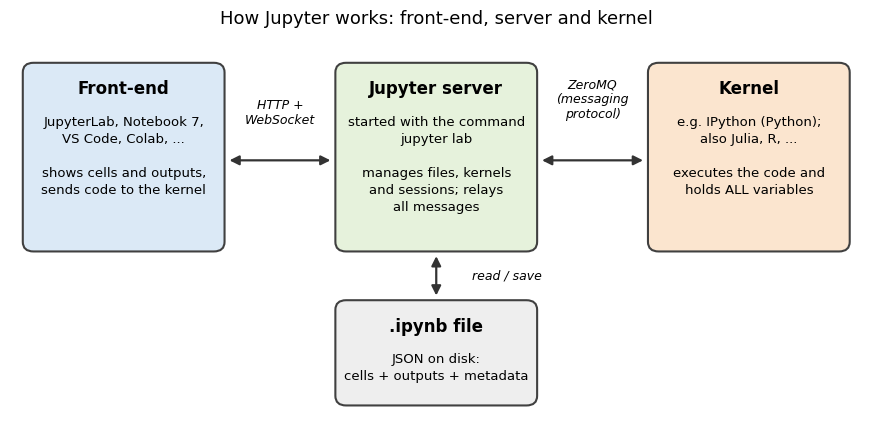

In [168]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.set(xlim=(0, 12), ylim=(0, 6))
ax.axis("off")                                         # a diagram needs no axes

draw_titled_box(ax, 0.2, 2.6, 2.8, 2.9, "Front-end", "JupyterLab, Notebook 7,\nVS Code, Colab, ...\n\n"
         "shows cells and outputs,\nsends code to the kernel", "#dbe9f6")
draw_titled_box(ax, 4.6, 2.6, 2.8, 2.9, "Jupyter server", "started with the command\njupyter lab\n\n"
         "manages files, kernels\nand sessions; relays\nall messages", "#e6f2dc")
draw_titled_box(ax, 9.0, 2.6, 2.8, 2.9, "Kernel", "e.g. IPython (Python);\nalso Julia, R, ...\n\n"
         "executes the code and\nholds ALL variables", "#fbe5cf")
draw_titled_box(ax, 4.6, 0.2, 2.8, 1.6, ".ipynb file", "JSON on disk:\ncells + outputs + metadata", "#eeeeee")

arrow = dict(arrowstyle="<|-|>", color="0.2", lw=1.6, mutation_scale=14)   # two-headed arrow
for start, end, label, xy in [((3.05, 4.0), (4.55, 4.0), "HTTP +\nWebSocket", (3.8, 4.75)),
                              ((7.45, 4.0), (8.95, 4.0), "ZeroMQ\n(messaging\nprotocol)", (8.2, 4.95)),
                              ((6.0, 2.55), (6.0, 1.85), "read / save", (7.0, 2.2))]:
    ax.annotate("", xy=end, xytext=start, arrowprops=arrow)
    ax.text(*xy, label, ha="center", va="center", fontsize=9, style="italic")

ax.set_title("How Jupyter works: front-end, server and kernel", fontsize=13)
plt.show()

- **The kernel holds the state.** All variables, imports and functions live in the kernel process, not in the document. After a kernel restart they are gone; the text and saved outputs remain.
- **An `.ipynb` file is plain JSON**: a list of cells (source and, for code cells, outputs) plus metadata such as the kernel name.

## 1.3 Getting started

We recommend a separate environment for the course. In a terminal (on Windows: *Anaconda Prompt* or *Miniforge Prompt* for conda), in the folder of this notebook:

```bash
# Option A: conda, using the environment.yml shipped with this notebook
conda env create -f environment.yml
conda activate jshare
jupyter lab

# Option B: pip and a virtual environment
python -m venv jshare-env
source jshare-env/bin/activate          # Windows: jshare-env\Scripts\activate
python -m pip install -r requirements.txt
jupyter lab
```

`jupyter lab` starts the server and opens JupyterLab in the browser; stop it with **Ctrl+C** in the terminal. To offer an environment as a kernel in another Jupyter installation, run `python -m ipykernel install --user --name jshare` inside it.

A `ModuleNotFoundError` for a package you *did* install usually means the kernel runs a different Python. The next cell shows which interpreter the kernel uses (home folder abbreviated as `~`).

In [169]:
home = str(Path.home())
print("Python version :", sys.version.split()[0])
print("Interpreter    :", sys.executable.replace(home, "~"))   # the kernel's Python
print("Environment    :", sys.prefix.replace(home, "~"))       # root folder of its environment
print("Operating sys. :", platform.system(), platform.machine())

Python version : 3.10.14
Interpreter    : ~/opt/anaconda3/envs/dlPDE/bin/python
Environment    : ~/opt/anaconda3/envs/dlPDE
Operating sys. : Darwin x86_64


On your computer the path should point into your course environment (e.g. `.../envs/jshare` for conda or `.../jshare-env` for pip; the saved output above comes from the author's machine). If not, choose the right kernel via **Kernel > Change Kernel...**, and install missing packages from inside the notebook with `%pip install ...`, which always targets the kernel's environment.

## 1.4 Cells, modes and shortcuts

A notebook is a sequence of **cells**:

- a **code cell** contains code for the kernel; running it shows the result below the cell;
- a **Markdown cell** contains formatted text and math; running it renders the text.

There are two keyboard modes. In **edit mode** (press **Enter** or click into a cell) you type into the cell. In **command mode** (press **Esc**) keys act on whole cells: insert, delete, change type.

| Action | Windows / Linux | macOS |
|---|---|---|
| Run cell and select the next one | Shift+Enter | Shift+Enter |
| Run cell and stay on it | Ctrl+Enter | Cmd+Enter |
| Enter edit mode / command mode | Enter / Esc | Enter / Esc |
| Insert cell above / below (command mode) | A / B | A / B |
| Delete cell (command mode) | D, D | D, D |
| Undo a cell operation (command mode) | Z | Z |
| Make cell Markdown / code (command mode) | M / Y | M / Y |
| Save | Ctrl+S | Cmd+S |
| Interrupt / restart kernel (command mode) | I, I / 0, 0 | I, I / 0, 0 |
| Command palette (JupyterLab) | Ctrl+Shift+C | Cmd+Shift+C |

These hold for JupyterLab 4 and Notebook 7 (VS Code has its own set); the full list is under **Settings > Settings Editor > Keyboard Shortcuts**.

> **Try it.** Select this cell, press **Esc**, then **B** (new cell below), **M** (Markdown), **Enter**, type a sentence and press **Ctrl+Enter** (macOS: **Cmd+Enter**) to render it and stay on the cell. Then press **Esc** and delete the cell again with **D, D**.

## 1.5 Markdown and LaTeX

Markdown is plain text with a few formatting symbols; math is written in LaTeX, with single dollars for inline and double dollars for displayed formulas (rendered by MathJax). **Double-click any Markdown cell to see its source.** This source ...

````markdown
Text can be *italic*, **bold** or `code`. The model problem of **Part 2** below:

- rod $(0,1)$, thermal diffusivity $\kappa > 0$, heat source $f$, initial temperature $u_0$,
- find the temperature $u(x,t)$ with $u(x,0) = u_0(x)$ such that
$$
u_t - \kappa\, u_{xx} = f \quad \text{in } (0,1) \times (0,T], \qquad u(0,t) = u(1,t) = 0 .
$$
````

... renders as:

Text can be *italic*, **bold** or `code`. The model problem of **Part 2** below:

- rod $(0,1)$, thermal diffusivity $\kappa > 0$, heat source $f$, initial temperature $u_0$,
- find the temperature $u(x,t)$ with $u(x,0) = u_0(x)$ such that
$$
u_t - \kappa\, u_{xx} = f \quad \text{in } (0,1) \times (0,T], \qquad u(0,t) = u(1,t) = 0 .
$$

> **Remark.** MathJax understands standard LaTeX *math* commands (`\frac`, `\nabla`, `\mathbf{u}`, `aligned`, ...) but not arbitrary packages; standard commands keep notebooks portable between JupyterLab, VS Code and GitHub.

## 1.6 Code cells and kernel state

The label `[n]:` to the left of a code cell is the **execution counter**: the cell was the $n$-th execution in this kernel session (`[*]` means "running or waiting to run"). Only the value of the **last expression** in a cell is displayed automatically; use `print()` for anything else.

In [170]:
a = 3
a * 2        # computed, but not displayed (not the last line)
a * 10       # the last expression is displayed

30

Variables persist: all cells share one kernel, so a name defined in one cell is available in every cell executed afterwards. Hence **the order in which you run cells matters, not the order in which they appear**. The next three cells, A, B and C, look harmless when run top to bottom.

In [171]:
x = 1                          # cell A

In [172]:
y = x + 1                      # cell B: y is computed from the CURRENT value of x

In [173]:
print(f"x = {x}, y = {y}")     # cell C

x = 1, y = 2


> **Try it.** Change cell A to `x = 100` and run **only** cell A, then **only** cell C. It prints `x = 100, y = 2`: the page shows `y = x + 1`, yet `y` was never recomputed, and the execution counters no longer increase from top to bottom. Afterwards change cell A back to `x = 1` and run A, B and C again.

> **Key idea.** A notebook is **not a spreadsheet**: a value is updated only when its cell is run again. Deleting a cell does not delete its variables either, so a notebook can silently depend on code that no longer exists (**hidden state**).

> **Pitfall.** The golden rule: before you share or trust a notebook, use **Kernel > Restart Kernel and Run All Cells...**. This discards all hidden state and runs every cell once, top to bottom, exactly as a reader will.

## 1.7 Rich output and magic commands

Outputs are not limited to text: figures, tables, HTML and formatted math appear directly below the cell. As a teaser for Part 2 below, we plot $u(x, t) = e^{-\pi^2 t}\sin(\pi x)$, which solves the heat equation $u_t = u_{xx}$ on $(0,1)$ with $u = 0$ at $x = 0$ and $x = 1$ and the initial temperature $u(x, 0) = \sin(\pi x)$.

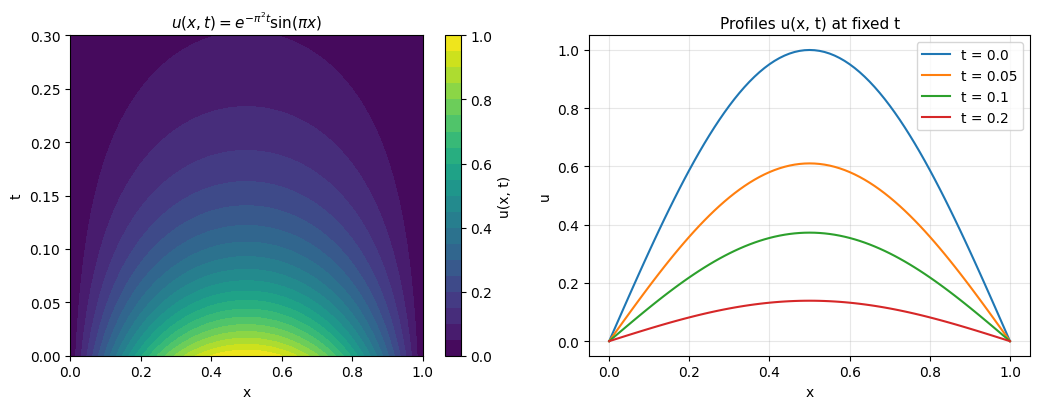

In [174]:
x_grid = np.linspace(0.0, 1.0, 81)                          # shape (81,)
t_grid = np.linspace(0.0, 0.3, 61)                          # shape (61,)
X_mesh, T_mesh = np.meshgrid(x_grid, t_grid, indexing="xy") # both of shape (61, 81): rows = t
u_mesh = np.exp(-np.pi**2 * T_mesh) * np.sin(np.pi * X_mesh)  # u(x, t) on the grid

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.2))
filled = ax1.contourf(X_mesh, T_mesh, u_mesh, levels=np.linspace(0.0, 1.0, 21),
                      cmap="viridis")
fig.colorbar(filled, ax=ax1, label="u(x, t)", ticks=np.linspace(0.0, 1.0, 6))
ax1.set(xlabel="x", ylabel="t", title=r"$u(x,t) = e^{-\pi^2 t}\sin(\pi x)$")

for t0 in [0.0, 0.05, 0.1, 0.2]:                            # temperature profiles u(x, t0)
    ax2.plot(x_grid, np.exp(-np.pi**2 * t0) * np.sin(np.pi * x_grid), label=f"t = {t0}")
ax2.set(xlabel="x", ylabel="u", title="Profiles u(x, t) at fixed t")
ax2.legend()
ax2.grid(alpha=0.3)
fig.tight_layout()
plt.show()

Observe: $u$ vanishes at $x = 0$ and $x = 1$ for all $t$ and decays in time; each profile is $\sin(\pi x)$ scaled by $e^{-\pi^2 t_0}$, so the peak value halves about every $0.07$ time units ($\ln 2/\pi^2 \approx 0.070$).

**Magic commands** are commands of the IPython kernel, not Python: line magics start with `%`, cell magics with `%%` (on the first line of the cell). `%timeit` runs a statement repeatedly and reports reliable timings. We compare a Python loop with NumPy for $\sum_i v_i^2$ over $10^5$ numbers; first the two versions and a check that they agree.

In [175]:
def sum_of_squares_loop(values):
    """Return sum(v**2) with a Python loop. values: list of floats, length n."""
    total = 0.0
    for v in values:
        total += v * v
    return total


def sum_of_squares_numpy(values):
    """Return sum(v**2) with NumPy. values: ndarray of shape (n,)."""
    return float(np.dot(values, values))      # dot product v . v in compiled code


rng = np.random.default_rng(seed=0)           # fixed seed -> reproducible numbers
values_array = rng.random(100_000)            # shape (100000,)
values_list = values_array.tolist()           # the same numbers as a Python list
print("results agree:", np.isclose(sum_of_squares_loop(values_list),
                                   sum_of_squares_numpy(values_array)))

results agree: True


Now the timings: `-n 20 -r 3` means 20 loops per run and 3 runs, and `-o` returns the result as an object, from which we compute the speed-up.

In [176]:
t_loop = %timeit -o -n 20 -r 3 sum_of_squares_loop(values_list)
t_numpy = %timeit -o -n 20 -r 3 sum_of_squares_numpy(values_array)
print(f"NumPy is roughly {t_loop.best / t_numpy.best:.0f} times faster here")

2.67 ms ± 26.3 µs per loop (mean ± std. dev. of 3 runs, 20 loops each)
14.7 µs ± 7.61 µs per loop (mean ± std. dev. of 3 runs, 20 loops each)
NumPy is roughly 388 times faster here


Observe: the vectorized version is about two orders of magnitude faster (the exact factor depends on your computer and varies between runs). This is why scientific Python code avoids loops over individual numbers.

Other useful magics (`%lsmagic` lists all of them):

| Magic | Purpose |
|---|---|
| `%who`, `%whos` | list the variables in the kernel (a quick look at hidden state) |
| `%%time` | time one run of a whole cell (CPU and wall-clock time) |
| `%%writefile name.py` | write the rest of the cell into a file |
| `%run script.py` | run a Python script; its variables then live in the notebook |
| `%pip install package` | install a package into the kernel's environment |
| `%debug` | open the debugger at the place of the last error |

## 1.8 Jupyter notebooks in teaching

**Why notebooks suit teaching.** Theory, code and results sit side by side: a derivation is followed immediately by its implementation and a figure. Students do not just read the lecture notes, they **run and modify** them: change a parameter and see what happens.

**Design tips for teaching notebooks.**

- Short cells, one idea per cell, and a sentence of explanation *before* each code cell.
- "Try it" prompts; exercises with hidden solutions in a collapsible `<details>` block.
- Fixed random seeds, printed library versions, and a `requirements.txt` or `environment.yml`.
- **Restart Kernel and Run All Cells** before distributing; hand out a copy with cleared outputs (**Edit > Clear Outputs of All Cells**) if students should produce the results themselves.

**Distributing and collecting work.**

- **GitHub** and **nbviewer** (nbviewer.org) display notebooks with their saved outputs as web pages.
- **Google Colab** or a course **JupyterHub** lets students run notebooks without installing anything.
- **nbgrader** creates student versions of assignments and helps collect and grade them; `jupyter nbconvert --to html file.ipynb` exports a static copy (`--to pdf` needs a LaTeX installation and pandoc).

## 1.9 AI assistance for preparing notebooks

Writing a good teaching notebook takes time, and AI tools can take over much of the routine work:

- **AI coding agents** such as **Claude Code** (Anthropic) or **Codex** (OpenAI) work with the files of your project. From a precise specification they can draft a complete notebook, execute it, inspect outputs and figures, and fix problems.
- **In-editor assistants** help cell by cell: the **Jupyter AI** extension adds a chat panel and AI magics to JupyterLab, and **GitHub Copilot** suggests code in VS Code notebooks.

A recommended workflow:

1. **Specify** topic, audience, length, libraries and section structure, as precisely as for a teaching assistant.
2. **Let the agent generate and execute** the notebook.
3. **Review critically**: the mathematics, the code and every number quoted in the text.
4. **Restart Kernel and Run All Cells**, and read the result once more as a student would.

> **Pitfall.** AI can produce plausible but wrong statements: a sign error, a fabricated reference, a convergence rate the output does not support. The lecturer stays responsible for correctness; AI speeds up the drafting, not the checking.

Parts 2 and 3 below were prepared with Claude Code in this way and then reviewed; a live demonstration is given separately.

## 1.10 Summary

- A notebook combines **code, text, math and results** in one executable document.
- The **front-end** displays, the **server** relays, the **kernel** computes and **holds all state**; an `.ipynb` file is JSON.
- The **execution order** determines the kernel state; always **Restart and Run All** before sharing.
- Notebooks are excellent **teaching material** that students can run and modify; AI agents can draft them, but the lecturer must review them.

**Cheat sheet**

| I want to ... | How |
|---|---|
| run a cell and go to the next | Shift+Enter (more shortcuts in Section 1.4) |
| write a formula | `$...$` inline, `$$...$$` displayed |
| time a statement / a cell | `%timeit stmt` / `%%time` |
| start from a clean state | Kernel > Restart Kernel and Run All Cells... |
| export to HTML | `jupyter nbconvert --to html file.ipynb` |

# Part 2: Finite Elements for the 1D Heat Equation

We solve the heat equation in one space dimension with **finite elements in space** and a **time-stepping scheme** for the resulting system of ordinary differential equations. Only **NumPy**, **SciPy** and **Matplotlib** are used; the method is written from scratch. Cells that only draw figures are collapsed (click the bar to their left to expand them).

## 2.1 The model problem

The temperature $u(x, t)$ in a thin rod of length 1 whose ends are kept at temperature 0 satisfies the **heat equation**

$$
\begin{aligned}
u_t - \kappa\, u_{xx} &= f && \text{in } (0,1) \times (0,T], \\
u(0,t) = u(1,t) &= 0 && \text{for } t \in (0,T], \\
u(x,0) &= u_0(x) && \text{for } x \in [0,1].
\end{aligned}
$$

Here $\kappa > 0$ is the **thermal diffusivity**, $f(x,t)$ a heat source and $u_0$ the initial temperature. Heat flows from warm to cold, so the temperature profile is smoothed out over time.

**Test case.** We take $f = 0$ and $u_0(x) = \sin(\pi x) + \tfrac12 \sin(3\pi x)$. Each function $\sin(k\pi x)$ vanishes at $x = 0$ and $x = 1$ and satisfies $-\partial_{xx}\sin(k\pi x) = k^2\pi^2 \sin(k\pi x)$, so it simply decays like $e^{-\kappa k^2\pi^2 t}$. The exact solution is therefore

$$
u(x,t) = e^{-\kappa\pi^2 t}\sin(\pi x) + \tfrac12\, e^{-9\kappa\pi^2 t}\sin(3\pi x).
$$

We take $\kappa = 0.1$ and $T = 0.5$. Up to $T$ the first mode decays to $e^{-0.05\pi^2} \approx 0.61$ of its initial size, but the fast mode $\sin(3\pi x)$ to $e^{-0.45\pi^2} \approx 0.012$: the two peaks of $u_0$ soon merge into a single arch. The next cell defines $u$, $u_x$ (needed for the errors in Section 2.6) and $u_0$.

In [177]:
KAPPA = 0.1          # thermal diffusivity kappa
T_FINAL = 0.5        # final time T


def u_exact(x, t, kappa=KAPPA):
    """Exact solution u(x, t) of the test case (f = 0).

    Args:
        x: positions in [0, 1], array of any shape.
        t: time, float or array broadcastable with x.  kappa: thermal diffusivity.
    Returns:
        array of the broadcast shape of x and t.
    """
    return (np.exp(-kappa * np.pi**2 * t) * np.sin(np.pi * x)
            + 0.5 * np.exp(-9 * kappa * np.pi**2 * t) * np.sin(3 * np.pi * x))


def u_exact_x(x, t, kappa=KAPPA):
    """Spatial derivative u_x(x, t) of u_exact (same arguments and shape)."""
    return (np.pi * np.exp(-kappa * np.pi**2 * t) * np.cos(np.pi * x)
            + 1.5 * np.pi * np.exp(-9 * kappa * np.pi**2 * t) * np.cos(3 * np.pi * x))


def u0(x):
    """Initial temperature u_0(x) = u(x, 0)."""
    return u_exact(x, 0.0)

## 2.2 Spatial discretization: finite elements

**Weak form.** Write $(w, v) = \int_0^1 w\,v\,dx$. Multiply the PDE by a test function $v$ with $v(0) = v(1) = 0$ and integrate the term $-\kappa\,(u_{xx}, v)$ by parts (the boundary terms vanish). For every $t \in (0,T]$:

$$
(u_t, v) + \kappa\,(u_x, v_x) = (f, v) \qquad \text{for all } v \in H^1_0(0,1).
$$

Here $H^1_0(0,1)$ is the space of functions $v$ with square-integrable $v_x$ and $v(0) = v(1) = 0$.

**Mesh and hat functions.** Take the uniform mesh $x_j = jh$, $j = 0, \dots, N$, with $h = 1/N$, and the **hat functions** $\varphi_j$: continuous, linear on each element $[x_{j-1}, x_j]$, with $\varphi_j(x_i) = \delta_{ij}$. We seek

$$
u_h(x,t) = \sum_{j=1}^{N-1} U_j(t)\,\varphi_j(x),
$$

so $U_j(t) = u_h(x_j, t)$, and $u_h = 0$ at the boundary nodes $x_0 = 0$ and $x_N = 1$.

**The ODE system.** Insert $u_h$ into the weak form and test with $v = \varphi_i$, $i = 1, \dots, N-1$. For $\mathbf{U}(t) = (U_1(t), \dots, U_{N-1}(t))^T$ this gives

$$
M\,\mathbf{U}'(t) + \kappa\,K\,\mathbf{U}(t) = \mathbf{F}(t),
$$

with $U_j(0) = u_0(x_j)$, i.e. $u_h(\cdot, 0)$ interpolates $u_0$. The **mass matrix**, **stiffness matrix** and **load vector** are $M_{ij} = (\varphi_j, \varphi_i)$, $K_{ij} = (\varphi_j', \varphi_i')$ and $F_i(t) = (f(\cdot, t), \varphi_i)$. Since $\varphi_i$ and $\varphi_j$ overlap only for $|i - j| \le 1$, $M$ and $K$ are **tridiagonal** $(N-1)\times(N-1)$ matrices:

$$
M = \frac{h}{6}\begin{pmatrix} 4 & 1 & & \\ 1 & 4 & \ddots & \\ & \ddots & \ddots & 1 \\ & & 1 & 4 \end{pmatrix}, \qquad
K = \frac{1}{h}\begin{pmatrix} 2 & -1 & & \\ -1 & 2 & \ddots & \\ & \ddots & \ddots & -1 \\ & & -1 & 2 \end{pmatrix}.
$$

On one element of length $h$, $\varphi_j' = \pm 1/h$, $\int \varphi_j^2\,dx = h/3$ and $\int \varphi_j\varphi_{j+1}\,dx = h/6$; each interior node belongs to two elements. In our test $\mathbf{F} = 0$; for $f \ne 0$ the $F_i$ are computed with a quadrature rule.

> **Key idea.** Finite elements in space turn the PDE into a system of ODEs in time, $M\mathbf{U}' + \kappa K\mathbf{U} = \mathbf{F}$ (the **method of lines**; see Larsson and Thomée, 2003, for an introduction). Now any ODE solver can be applied.

The next cell shows the mesh for $N = 8$, three hat functions (each nonzero only on the two elements next to its node), and $u_0$ with its interpolant $u_h(\cdot, 0)$.

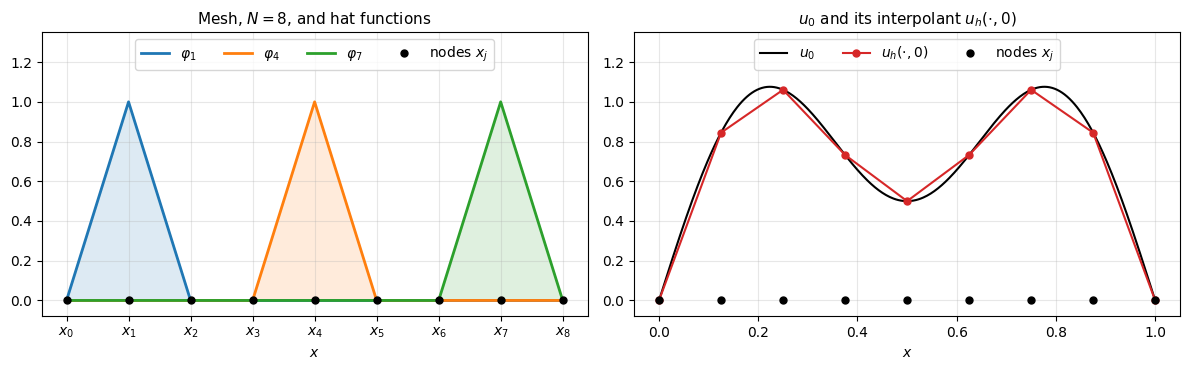

In [178]:
N_demo = 8
x_nodes = np.linspace(0.0, 1.0, N_demo + 1)                  # mesh nodes x_j = j h
x_fine = np.linspace(0.0, 1.0, 401)                          # for smooth curves

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for j, color in [(1, "C0"), (4, "C1"), (7, "C2")]:
    phi_j = np.interp(x_fine, x_nodes, np.eye(N_demo + 1)[j])    # hat function phi_j
    axes[0].plot(x_fine, phi_j, color=color, lw=2, label=rf"$\varphi_{j}$")
    axes[0].fill_between(x_fine, phi_j, color=color, alpha=0.15)
axes[0].plot(x_nodes, np.zeros_like(x_nodes), "ko", ms=5, label="nodes $x_j$")
axes[0].set_xticks(x_nodes, [f"$x_{{{j}}}$" for j in range(N_demo + 1)])
axes[0].set(ylim=(-0.08, 1.35), xlabel="$x$", title=f"Mesh, $N = {N_demo}$, and hat functions")
axes[0].legend(loc="upper center", ncol=4)

axes[1].plot(x_fine, u0(x_fine), "k-", lw=1.5, label="$u_0$")
axes[1].plot(x_nodes, u0(x_nodes), "o-", color="C3", ms=5, label=r"$u_h(\cdot, 0)$")
axes[1].plot(x_nodes, np.zeros_like(x_nodes), "ko", ms=5, label="nodes $x_j$")
axes[1].set(ylim=(-0.08, 1.35), xlabel="$x$", title=r"$u_0$ and its interpolant $u_h(\cdot, 0)$")
axes[1].legend(loc="upper center", ncol=3)
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 2.3 Time discretization: solving the ODE system

Choose a time step $\Delta t = T/N_t$ (`n_steps` $= N_t$ in the code), time levels $t_n = n\,\Delta t$ and approximations $\mathbf{U}^n \approx \mathbf{U}(t_n)$. The **$\theta$-scheme** replaces $\mathbf{U}'$ by $(\mathbf{U}^{n+1} - \mathbf{U}^n)/\Delta t$ and the other terms by the weighted average of their values at $t_{n+1}$ (weight $\theta$) and $t_n$ (weight $1-\theta$). With $\mathbf{F}^{n+\theta} = \theta\,\mathbf{F}(t_{n+1}) + (1-\theta)\,\mathbf{F}(t_n)$ it reads

$$
\big(M + \theta\,\kappa\,\Delta t\,K\big)\,\mathbf{U}^{n+1} = \big(M - (1-\theta)\,\kappa\,\Delta t\,K\big)\,\mathbf{U}^{n} + \Delta t\,\mathbf{F}^{n+\theta}.
$$

- $\theta = 0$: **explicit (forward) Euler**, order 1 in $\Delta t$;
- $\theta = 1$: **backward (implicit) Euler**, order 1;
- $\theta = 1/2$: **Crank-Nicolson**, order 2 (Crank and Nicolson, 1947).

**Why implicit? The system is stiff.** The eigenvalues $\lambda$ of $M^{-1}K$ range from about $\pi^2$ (the smooth mode $\sin(\pi x)$) to about $12/h^2$ (a mode that changes sign from node to node). Explicit Euler multiplies each mode by $1 - \kappa\,\Delta t\,\lambda$ per step and is therefore stable only for

$$
\Delta t \le \frac{2}{\kappa\,\lambda_{\max}} \approx \frac{h^2}{6\kappa},
$$

i.e. $\Delta t \le 1.6\cdot 10^{-3}$ for $N = 32$ and $\kappa = 0.1$; halving $h$ divides the admissible step by four. Backward Euler and Crank-Nicolson are **unconditionally stable**: the step can be as large as the accuracy allows.

**Cost.** The matrix $M + \theta\kappa\Delta t K$ is the same in every step, so we **factorize it once** (sparse LU, `scipy.sparse.linalg.splu`) and reuse the factors; each step then costs $O(N)$ operations.

## 2.4 Implementation

**(a) The matrices.** `sp.diags` builds a sparse matrix from its diagonals, here in the CSC format that `splu` expects. The cell prints $\tfrac{6}{h}M$ and $hK$ for $N = 5$ and checks the stability bound of Section 2.3: $\lambda_{\max} h^2$ should approach 12, and $2/(\kappa\lambda_{\max})$ should be close to $h^2/(6\kappa)$.

In [179]:
def assemble_matrices(N):
    """P1 mass and stiffness matrix on the uniform mesh x_j = j/N (interior nodes only).

    Args:
        N: number of elements (int >= 2); the unknowns are the N-1 interior nodal values.
    Returns:
        M, K: sparse (N-1, N-1) CSC matrices with h = 1/N,
              M = (h/6) tridiag(1, 4, 1) and K = (1/h) tridiag(-1, 2, -1).
    """
    h, n = 1.0 / N, N - 1
    M = sp.diags([1.0, 4.0, 1.0], [-1, 0, 1], shape=(n, n), format="csc") * (h / 6)
    K = sp.diags([-1.0, 2.0, -1.0], [-1, 0, 1], shape=(n, n), format="csc") / h
    return M, K


M, K = assemble_matrices(5)                                  # h = 1/5
print("6/h * M =\n", (6 * 5 * M).toarray().round(12))
print("h * K =\n", (K / 5).toarray().round(12))

for N in [16, 32, 64]:
    M, K = assemble_matrices(N)
    h = 1.0 / N
    MinvK = np.linalg.solve(M.toarray(), K.toarray())        # dense M^-1 K, (N-1, N-1)
    lam_max = np.linalg.eigvals(MinvK).real.max()            # largest eigenvalue
    print(f"N = {N:2d}: lambda_max h^2 = {lam_max * h**2:6.3f},  2/(kappa lambda_max) = "
          f"{2 / (KAPPA * lam_max):.3e},  h^2/(6 kappa) = {h**2 / (6 * KAPPA):.3e}")

6/h * M =
 [[4. 1. 0. 0.]
 [1. 4. 1. 0.]
 [0. 1. 4. 1.]
 [0. 0. 1. 4.]]
h * K =
 [[ 2. -1.  0.  0.]
 [-1.  2. -1.  0.]
 [ 0. -1.  2. -1.]
 [ 0.  0. -1.  2.]]
N = 16: lambda_max h^2 = 11.661,  2/(kappa lambda_max) = 6.700e-03,  h^2/(6 kappa) = 6.510e-03
N = 32: lambda_max h^2 = 11.914,  2/(kappa lambda_max) = 1.639e-03,  h^2/(6 kappa) = 1.628e-03
N = 64: lambda_max h^2 = 11.978,  2/(kappa lambda_max) = 4.076e-04,  h^2/(6 kappa) = 4.069e-04


**Observe.** The patterns match Section 2.2, and $\lambda_{\max} h^2 \to 12$. The exact explicit limit is slightly larger than $h^2/(6\kappa)$, so $h^2/(6\kappa)$ is a safe and sharp rule of thumb.

**(b) The solver.** `solve_heat` implements the $\theta$-scheme with $\mathbf{F} = 0$ and returns the nodal values at all time levels, boundary zeros included, as an array of shape `(n_steps + 1, N + 1)`: row $n$ holds $u_h(x_j, t_n)$, $j = 0, \dots, N$. We run it with $N = 32$ and Crank-Nicolson with $N_t = 200$ steps, i.e. $\Delta t = 2.5\cdot 10^{-3}$, above the explicit limit $1.6\cdot 10^{-3}$.

> **Try it.** Change `0.5` to `0.0` (explicit Euler) in the call below and run the cell again: the step is too large and the error explodes, although the data are smooth (round-off excites the unstable mode). Then change it back.

In [180]:
def solve_heat(N, n_steps, T, theta, kappa, u0):
    """theta-scheme for M U' + kappa K U = 0 (P1 elements in space, u = 0 at x = 0 and x = 1).

    Args:
        N: number of elements (h = 1/N).  n_steps: number of time steps N_t (dt = T / n_steps).
        T: final time.  theta: 0 explicit Euler, 1 backward Euler, 0.5 Crank-Nicolson.
        kappa: thermal diffusivity.  u0: initial temperature, a function of x (NumPy arrays).
    Returns:
        x: (N+1,) nodes.  t: (n_steps+1,) time levels.
        U: (n_steps+1, N+1) nodal values, U[n, j] = u_h(x_j, t_n); the boundary columns are 0.
    """
    x = np.linspace(0.0, 1.0, N + 1)                       # nodes x_j = j h
    t = np.linspace(0.0, T, n_steps + 1)                   # time levels t_n = n dt
    dt = T / n_steps
    M, K = assemble_matrices(N)                            # (N-1, N-1) each
    lu = spla.splu((M + theta * kappa * dt * K).tocsc())   # factorize the left matrix once
    B = (M - (1 - theta) * kappa * dt * K).tocsr()         # right matrix
    U = np.zeros((n_steps + 1, N + 1))
    U[0, 1:-1] = u0(x[1:-1])                               # U^0: nodal interpolant of u0
    for n in range(n_steps):
        U[n + 1, 1:-1] = lu.solve(B @ U[n, 1:-1])          # one theta-step (F = 0)
    return x, t, U


start = time.perf_counter()
x, t, U = solve_heat(32, 200, T_FINAL, 0.5, KAPPA, u0)     # N = 32, Crank-Nicolson
print(f"U has shape {U.shape}; 200 steps took {1e3 * (time.perf_counter() - start):.1f} ms")
print(f"max nodal error over all t_n: {np.abs(U - u_exact(x[None, :], t[:, None])).max():.2e}")

U has shape (201, 33); 200 steps took 3.7 ms
max nodal error over all t_n: 1.37e-03


## 2.5 Numerical results

Three standard views of a time-dependent 1D solution, all for the run above ($N = 32$, Crank-Nicolson, $\Delta t = 2.5\cdot 10^{-3}$): snapshots, a movie and a space-time plot.

**(a) Snapshots.** $u_h(\cdot, t_n)$ at a few times (markers at the nodes, joined by straight lines since $u_h$ is piecewise linear) and the exact solution (thin black lines). Unlike a movie, a static figure also survives the export to PDF.

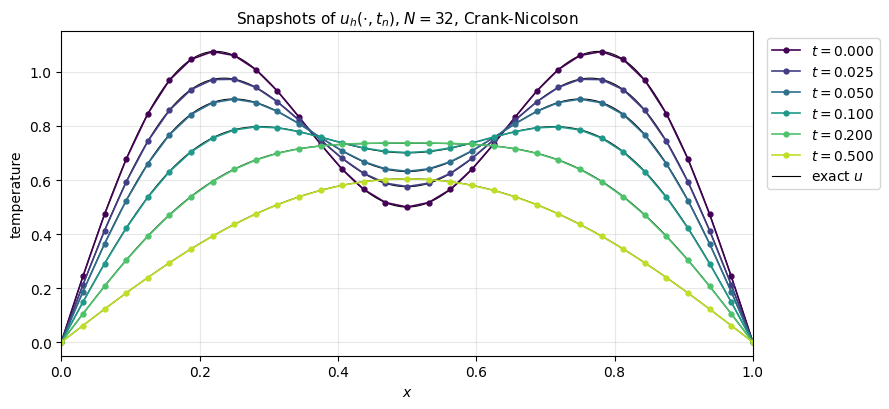

In [181]:
x_fine = np.linspace(0.0, 1.0, 401)
snapshot_steps = [0, 10, 20, 40, 80, 200]                  # t_n = n dt with dt = 0.0025
colors = matplotlib.colormaps["viridis"](np.linspace(0.0, 0.9, len(snapshot_steps)))

fig, ax = plt.subplots(figsize=(9, 4.2))
for n, color in zip(snapshot_steps, colors):
    ax.plot(x_fine, u_exact(x_fine, t[n]), "k-", lw=0.8)
    ax.plot(x, U[n], "o-", color=color, ms=3.5, lw=1.2, label=f"$t = {t[n]:.3f}$")
ax.plot([], [], "k-", lw=0.8, label="exact $u$")
ax.set(xlim=(0, 1), ylim=(-0.05, 1.15), xlabel="$x$", ylabel="temperature",
       title=r"Snapshots of $u_h(\cdot, t_n)$, $N = 32$, Crank-Nicolson")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))     # legend right of the axes
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Observe.** The dip between the two peaks of $u_0$ fills up quickly, because the $\sin(3\pi x)$ mode decays nine times faster than the $\sin(\pi x)$ mode; at about $t = 0.2$ only a single arch is left, which then slowly shrinks. At every time the finite element solution lies on top of the exact one.

**(b) A movie.** `FuncAnimation` calls `update` for every frame, and `to_jshtml()` turns the frames into an interactive HTML/JavaScript player with play, pause and a time slider (no ffmpeg needed). To keep the file small we show every fifth time level (41 frames) at a low resolution; `plt.close(fig)` prevents an extra static figure. This drawing cell is not collapsed, since animations are a Jupyter feature worth knowing.

> **Remark.** The player uses JavaScript: in a saved notebook it may only work after re-running the cell or trusting the notebook (**File > Trust Notebook**, or **Trust Notebook** in the JupyterLab command palette).

In [ ]:
skip = 5                                                   # every 5th time level: 41 frames
x_fine = np.linspace(0.0, 1.0, 401)                        # for the exact solution
fig, ax = plt.subplots(figsize=(6.4, 3.4))
line_exact, = ax.plot([], [], "k-", lw=1.5, label="exact $u$")
line_fem, = ax.plot([], [], "o-", color="C1", ms=3, lw=1, label="FEM $u_h$")
ax.set(xlim=(0, 1), ylim=(-0.05, 1.3), xlabel="$x$", ylabel="temperature")
ax.legend(loc="upper center", ncol=2)


def update(k):
    """Draw frame k, i.e. the time level n = k * skip; return the changed artists."""
    n = k * skip
    line_exact.set_data(x_fine, u_exact(x_fine, t[n]))
    line_fem.set_data(x, U[n])
    ax.set_title(f"Heat equation, $N = 32$, Crank-Nicolson:  $t = {t[n]:.3f}$")
    return line_exact, line_fem


anim = FuncAnimation(fig, update, frames=len(t[::skip]), interval=120)
plt.close(fig)                                             # no extra static figure
with plt.rc_context({"savefig.dpi": 80}):                  # resolution of the movie frames
    player = HTML(anim.to_jshtml())                        # interactive player (HTML + JS)
player

**(c) Space-time plot.** Since $x$ is one-dimensional, the whole history fits into one picture: $x$ horizontal, $t$ vertical and the colour showing $u_h(x, t)$. For the colour plot we evaluate $u_h(\cdot, t_n)$ on a fine grid in $x$ with `np.interp`, which is exact for the piecewise linear $u_h$. Next to it, filled contours show the error at the nodes and time levels, $|u(x_j, t_n) - u_h(x_j, t_n)|$.

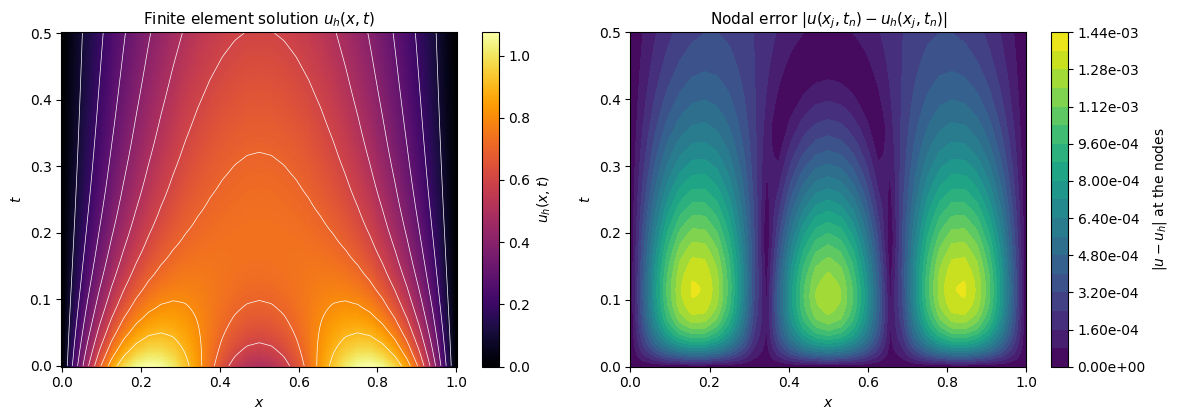

In [183]:
x_plot = np.linspace(0.0, 1.0, 201)                        # fine grid in x
uh_plot = np.array([np.interp(x_plot, x, U_n) for U_n in U])   # u_h(x, t_n), (n_steps+1, 201)
X_nodes, T_nodes = np.meshgrid(x, t)                       # both (n_steps+1, N+1), like U
error = np.abs(u_exact(X_nodes, T_nodes) - U)              # |u(x_j, t_n) - u_h(x_j, t_n)|; U[n, j] = u_h(x_j, t_n)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
pm = axes[0].pcolormesh(x_plot, t, uh_plot, shading="nearest", cmap="inferno")
fig.colorbar(pm, ax=axes[0], label="$u_h(x, t)$")
axes[0].contour(x_plot, t, uh_plot, levels=np.linspace(0.1, 0.9, 9), colors="w", linewidths=.5)
axes[0].set_title("Finite element solution $u_h(x, t)$")
pe = axes[1].contourf(X_nodes, T_nodes, error, levels=20, cmap="viridis")
fig.colorbar(pe, ax=axes[1], label="$|u - u_h|$ at the nodes", format="%.2e")
axes[1].set_title("Nodal error $|u(x_j, t_n) - u_h(x_j, t_n)|$")
for ax in axes:
    ax.set(xlabel="$x$", ylabel="$t$")
plt.tight_layout()
plt.show()

**Observe.** The two warm bands of $u_0$ (bottom) join quickly; then the arch fades slowly (white level lines $0.1, 0.2, \dots, 0.9$). The error vanishes at $x = 0$ and $x = 1$ and has the shape of $|\sin(3\pi x)|$: the discrete fast mode decays slightly too fast. The error is largest, $1.37\cdot 10^{-3}$ (the maximum printed in Section 2.4), near $t = 1/(9\kappa\pi^2) \approx 0.11$, and then decays with the mode.

## 2.6 Error analysis

Let $u_h^n = \sum_j U^n_j \varphi_j$ be the fully discrete solution at $t_n$. For a smooth solution, as in our test, and with the interpolant of $u_0$ as initial value, the classical estimates read (see Thomée, 2006, Chapter 1)

$$
\|u(t_n) - u_h^n\|_{L^2} \le C\,\big(h^2 + \Delta t^{\,p}\big), \qquad |u(t_n) - u_h^n|_{H^1} \le C\,\big(h + \Delta t^{\,p}\big),
$$

with $p = 1$ for backward Euler and $p = 2$ for Crank-Nicolson. Here $|v|_{H^1} = \|v_x\|_{L^2}$ is the $H^1$-seminorm, and $C$ depends on $u$ and $T$ but not on $h$ and $\Delta t$. In space the orders are those of a stationary problem (interpolation and elliptic error estimates, see Brenner and Scott, 2008); $H^1$ loses one order because the derivative of $u_h$ is only piecewise constant.

**Computing the errors.** Let $e = u(\cdot, T) - u_h^{N_t}$ be the error at the final time. Both $\|e\|_{L^2}^2$ and $|e|_{H^1}^2 = \|e_x\|_{L^2}^2$ are sums of integrals over the elements $[x_{j-1}, x_j]$, on which $u_h^{N_t}$ is linear with slope $(U_j - U_{j-1})/h$. We evaluate each integral with the 3-point **Gauss-Legendre rule** (exact for polynomials of degree $\le 5$; `np.polynomial.legendre.leggauss`). The **observed order** between consecutive runs is $\mathrm{EOC} = \log(e_{k-1}/e_k) / \log(s_{k-1}/s_k)$, with $s = h$ or $s = \Delta t$, so that $e \approx C s^{\mathrm{EOC}}$.

In [184]:
GAUSS_X, GAUSS_W = np.polynomial.legendre.leggauss(3)      # points, weights on [-1, 1], (3,)


def fem_errors(x, U_end, T, kappa=KAPPA):
    """L2 error and H1-seminorm error of the P1 function with nodal values U_end at time T.

    Args:
        x: (N+1,) nodes.  U_end: (N+1,) nodal values of u_h at time T.
        T: time.  kappa: thermal diffusivity.
    Returns:
        err_L2, err_H1: floats.
    """
    h = np.diff(x)[:, None]                                # (N, 1) element lengths
    xq = (x[:-1, None] + x[1:, None]) / 2 + h / 2 * GAUSS_X    # (N, 3) quadrature points
    w = h / 2 * GAUSS_W                                    # (N, 3) mapped weights
    s = (xq - x[:-1, None]) / h                            # (N, 3) local coordinate in [0, 1]
    uh = (1 - s) * U_end[:-1, None] + s * U_end[1:, None]  # (N, 3) u_h at the points
    duh = np.diff(U_end)[:, None] / h                      # (N, 1) constant slope of u_h
    err_L2 = np.sqrt(np.sum(w * (u_exact(xq, T, kappa) - uh)**2))
    err_H1 = np.sqrt(np.sum(w * (u_exact_x(xq, T, kappa) - duh)**2))
    return err_L2, err_H1


def eoc(err, step):
    """Observed orders log(e[k-1]/e[k]) / log(s[k-1]/s[k]); (K,) arrays -> (K-1,) array."""
    err, step = np.asarray(err), np.asarray(step)
    return np.log(err[:-1] / err[1:]) / np.log(step[:-1] / step[1:])

**(i) Convergence in space.** Crank-Nicolson on the meshes $N = 8, 16, \dots, 256$ with the fixed small step $\Delta t = 10^{-4}$ ($N_t = 5000$). Its time error, of order $\Delta t^2 = 10^{-8}$, is far below the space errors; the last line checks this by repeating the finest run with half the step. We expect EOC $\approx 2$ in $L^2$ and $\approx 1$ in $H^1$.

In [185]:
Ns = [8, 16, 32, 64, 128, 256]
N_STEPS_FINE = 5000                                        # dt = T / 5000 = 1e-4
errors = []
for N in Ns:
    x_N, _, U_N = solve_heat(N, N_STEPS_FINE, T_FINAL, 0.5, KAPPA, u0)
    errors.append(fem_errors(x_N, U_N[-1], T_FINAL))
err_L2_h, err_H1_h = np.array(errors).T                    # (6,) each
h_values = 1.0 / np.array(Ns)
eoc_L2 = ["-"] + [f"{v:.2f}" for v in eoc(err_L2_h, h_values)]
eoc_H1 = ["-"] + [f"{v:.2f}" for v in eoc(err_H1_h, h_values)]
print(f"{'N':>5} {'h':>9} {'L2 error':>10} {'EOC':>5} {'H1 error':>10} {'EOC':>5}")
for k, N in enumerate(Ns):
    print(f"{N:>5} {h_values[k]:>9.5f} {err_L2_h[k]:>10.2e} {eoc_L2[k]:>5} "
          f"{err_H1_h[k]:>10.2e} {eoc_H1[k]:>5}")

x_N, _, U_N = solve_heat(Ns[-1], 2 * N_STEPS_FINE, T_FINAL, 0.5, KAPPA, u0)   # half the step
change = abs(fem_errors(x_N, U_N[-1], T_FINAL)[0] - err_L2_h[-1]) / err_L2_h[-1]
print(f"N = {Ns[-1]}: halving dt changes the L2 error by only {change:.2e} (relative change)")

    N         h   L2 error   EOC   H1 error   EOC
    8   0.12500   8.82e-03     -   1.55e-01     -
   16   0.06250   2.24e-03  1.97   7.73e-02  1.00
   32   0.03125   5.64e-04  1.99   3.86e-02  1.00
   64   0.01562   1.41e-04  2.00   1.93e-02  1.00
  128   0.00781   3.53e-05  2.00   9.65e-03  1.00
  256   0.00391   8.83e-06  2.00   4.82e-03  1.00
N = 256: halving dt changes the L2 error by only 4.34e-05 (relative change)


**(ii) Convergence in time.** Now the reverse: the fine mesh $N = 10^4$, with an $L^2$ space error of about $6\cdot 10^{-9}$ (by the $h^2$ law and the table above), and $N_t = 10, 20, \dots, 320$ steps of backward Euler and Crank-Nicolson. We expect EOC $\approx 1$ and $\approx 2$. We use only the $L^2$ error: the space part of the $H^1$ error, about $10^{-4}$ here, would hide the small Crank-Nicolson time errors.

In [186]:
N_FINE = 10_000                                            # h = 1e-4
step_counts = [10, 20, 40, 80, 160, 320]
dt_values = T_FINAL / np.array(step_counts)
err_L2_dt = {}                                             # scheme name -> (6,) L2 errors
for name, theta in [("backward Euler", 1.0), ("Crank-Nicolson", 0.5)]:
    errs = []
    for n_steps in step_counts:
        x_N, _, U_N = solve_heat(N_FINE, n_steps, T_FINAL, theta, KAPPA, u0)
        errs.append(fem_errors(x_N, U_N[-1], T_FINAL)[0])
    err_L2_dt[name] = np.array(errs)

be, cn = err_L2_dt["backward Euler"], err_L2_dt["Crank-Nicolson"]
eoc_be = ["-"] + [f"{v:.2f}" for v in eoc(be, dt_values)]
eoc_cn = ["-"] + [f"{v:.2f}" for v in eoc(cn, dt_values)]
print(f"{'N_t':>5} {'dt':>9} {'BE error':>10} {'EOC':>5} {'CN error':>10} {'EOC':>5}")
for k, n_steps in enumerate(step_counts):
    print(f"{n_steps:>5} {dt_values[k]:>9.5f} {be[k]:>10.2e} {eoc_be[k]:>5} "
          f"{cn[k]:>10.2e} {eoc_cn[k]:>5}")

  N_t        dt   BE error   EOC   CN error   EOC
   10   0.05000   7.02e-03     -   3.05e-04     -
   20   0.02500   3.43e-03  1.03   7.67e-05  1.99
   40   0.01250   1.69e-03  1.02   1.92e-05  2.00
   80   0.00625   8.40e-04  1.01   4.80e-06  2.00
  160   0.00313   4.18e-04  1.01   1.20e-06  2.00
  320   0.00156   2.09e-04  1.00   3.02e-07  1.99


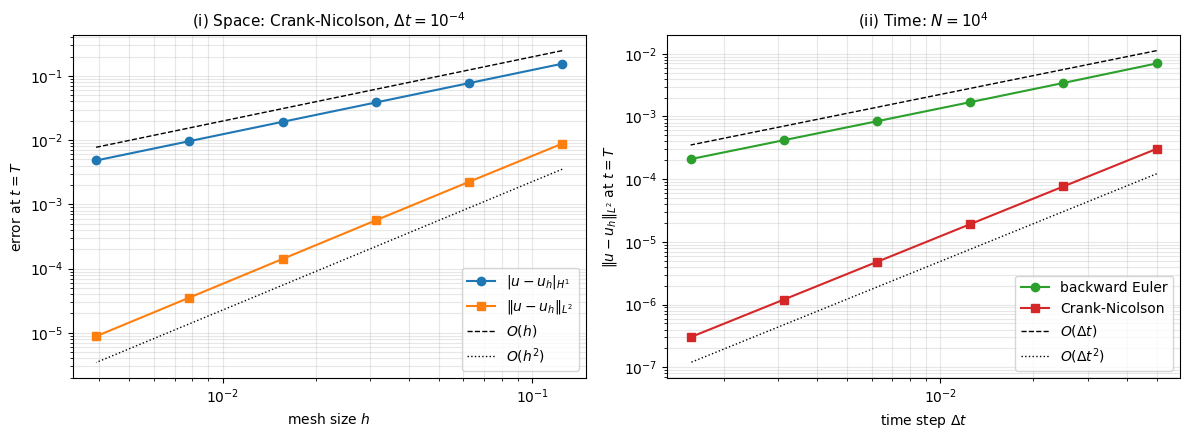

In [187]:
def reference_slope(ax, x, y_start, order, label, style="k--"):
    """Draw the line y_start * (x / x[0])^order on a log-log axis."""
    x = np.asarray(x, dtype=float)
    ax.loglog(x, y_start * (x / x[0])**order, style, lw=1, label=label)


fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].loglog(h_values, err_H1_h, "o-", label=r"$|u - u_h|_{H^1}$")
axes[0].loglog(h_values, err_L2_h, "s-", label=r"$\|u - u_h\|_{L^2}$")
reference_slope(axes[0], h_values, 1.6 * err_H1_h[0], 1, r"$O(h)$")
reference_slope(axes[0], h_values, 0.4 * err_L2_h[0], 2, r"$O(h^2)$", "k:")
axes[0].set(xlabel="mesh size $h$", ylabel="error at $t = T$",
            title=r"(i) Space: Crank-Nicolson, $\Delta t = 10^{-4}$")
axes[1].loglog(dt_values, be, "o-", color="C2", label="backward Euler")
axes[1].loglog(dt_values, cn, "s-", color="C3", label="Crank-Nicolson")
reference_slope(axes[1], dt_values, 1.6 * be[0], 1, r"$O(\Delta t)$")
reference_slope(axes[1], dt_values, 0.4 * cn[0], 2, r"$O(\Delta t^2)$", "k:")
axes[1].set(xlabel=r"time step $\Delta t$", ylabel=r"$\|u - u_h\|_{L^2}$ at $t = T$",
            title=r"(ii) Time: $N = 10^4$")
for ax in axes:
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

**Observe.** (i) In space the observed orders approach 2.00 in $L^2$ and 1.00 in $H^1$, and halving $\Delta t$ changes the finest $L^2$ error by less than $10^{-4}$ of its size: these are pure space errors. (ii) In time backward Euler shows order 1 (halving $\Delta t$ halves the error) and Crank-Nicolson order 2 (halving $\Delta t$ quarters it). For the same step, Crank-Nicolson is 20 to 700 times more accurate here, at the same cost per step.

> **Key idea.** Convergence tables are the standard test of a PDE code: the observed orders agree with the theory only if discretization **and** implementation are correct. To see the order in one variable, make the error in the other one negligible, and check that it is.

## 2.7 Summary

- **Method of lines:** P1 finite elements in space turn the heat equation into the ODE system $M\mathbf{U}' + \kappa K\mathbf{U} = \mathbf{F}$ with the tridiagonal matrices $M = \tfrac{h}{6}\,\mathrm{tridiag}(1, 4, 1)$ and $K = \tfrac{1}{h}\,\mathrm{tridiag}(-1, 2, -1)$.
- **Time stepping:** the system is stiff ($\lambda_{\max} \approx 12/h^2$), so explicit Euler needs $\Delta t \lesssim h^2/(6\kappa)$; backward Euler and Crank-Nicolson are unconditionally stable, and with one LU factorization each step costs $O(N)$.
- **Presentation:** snapshots, an interactive movie (`FuncAnimation` + `to_jshtml`) and a space-time plot show how the fast mode dies out and the remaining arch slowly decays.
- **Error analysis:** $\|u - u_h\|_{L^2} = O(h^2 + \Delta t^p)$ and $|u - u_h|_{H^1} = O(h + \Delta t^p)$, with $p = 1$ (backward Euler) and $p = 2$ (Crank-Nicolson); the experiments confirm the orders 2 and 1 in space and 1 and 2 in time.

# Part 3: Physics-Informed Neural Networks for the 2D Navier-Stokes Equations

**Setup for Part 3.** This part additionally needs **PyTorch** (neural networks and automatic differentiation). The next cell imports it and chooses the device and the precision. We use an NVIDIA GPU via `cuda` if available, otherwise the CPU, and float32 precision. We skip Apple's `mps` backend: it lacks float64, and for networks this small the overhead of many tiny GPU operations outweighs any speed-up. As in Part 2, the code of a few cells that only draw figures is collapsed.

In [188]:
# PyTorch may import the progress-bar package tqdm internally; without the optional ipywidgets
# package, tqdm then prints a harmless "IProgress not found" warning. We silence exactly this one.
warnings.filterwarnings("ignore", message="IProgress not found")

import torch
import torch.nn as nn

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE = torch.float32
torch.set_num_threads(min(8, os.cpu_count() or 1))   # small networks: few threads are often faster

print(f"PyTorch {torch.__version__} | device: {DEVICE}, dtype: {DTYPE}, CPU threads: {torch.get_num_threads()}")

PyTorch 2.2.2 | device: cpu, dtype: torch.float32, CPU threads: 8


## 3.1 What is a PINN?

A **physics-informed neural network (PINN)** is a neural network that is trained to *satisfy a differential equation* together with its boundary conditions. It learns mostly from the equation itself, not from many input-output examples. The idea goes back to Lagaris et al. (1998) and was popularized by Raissi et al. (2019); Karniadakis et al. (2021) give a review.

**The network.** We use a feed-forward network, also called a **multilayer perceptron (MLP)**. It alternates affine maps with a scalar **activation function** $\sigma$ applied componentwise (we will use $\sigma = \tanh$):

$$
\begin{aligned}
\mathbf{z}^{(0)} &= \mathbf{x}, \qquad
\mathbf{z}^{(\ell)} = \sigma\big(W^{(\ell)}\mathbf{z}^{(\ell-1)} + \mathbf{b}^{(\ell)}\big), \quad \ell = 1,\dots,L-1 \quad\text{(hidden layers)},\\
u_\theta(\mathbf{x}) &= W^{(L)}\mathbf{z}^{(L-1)} + \mathbf{b}^{(L)} \quad\text{(linear output layer)}.
\end{aligned}
$$

All weights $W^{(\ell)}$ and biases $\mathbf{b}^{(\ell)}$ form the parameter vector $\theta$. The next cell draws the usual picture of such a network, with the inputs and outputs of our Navier-Stokes PINN (its drawing code is collapsed).

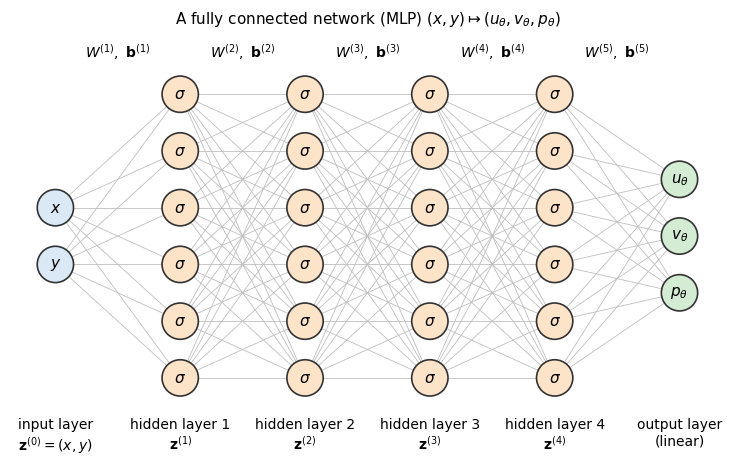

In [189]:
def draw_mlp(ax, layer_sizes, input_labels, output_labels, dx=2.2, dy=1.0, radius=0.32):
    """Draw a fully connected feed-forward network: circles = neurons, lines = weights.

    Args:
        ax: Matplotlib axes.
        layer_sizes: number of neurons drawn in each layer, e.g. [2, 6, 6, 6, 6, 3].
        input_labels, output_labels: texts written into the input and output neurons.
        dx, dy: horizontal distance of the layers and vertical distance of the neurons.
        radius: radius of the neuron circles.
    """
    centers = [np.column_stack([np.full(n, dx * l), ((n - 1) / 2 - np.arange(n)) * dy])
               for l, n in enumerate(layer_sizes)]               # (n_l, 2) centres, first neuron on top
    for left, right in zip(centers[:-1], centers[1:]):           # every pair of neurons in
        for x0, y0 in left:                                      # neighbouring layers is
            for x1, y1 in right:                                 # connected by one weight
                ax.plot([x0, x1], [y0, y1], color="0.75", lw=0.6, zorder=1)
    n_layers = len(layer_sizes)
    for l, layer in enumerate(centers):
        is_input, is_output = l == 0, l == n_layers - 1
        color = "#dbe9f6" if is_input else "#d5ecd4" if is_output else "#fde3c8"
        labels = input_labels if is_input else output_labels if is_output else [r"$\sigma$"] * len(layer)
        for (x, y), label in zip(layer, labels):
            ax.add_patch(plt.Circle((x, y), radius, facecolor=color, edgecolor="0.2", lw=1.2, zorder=2))
            ax.text(x, y, label, ha="center", va="center", fontsize=11, zorder=3)


fig, ax = plt.subplots(figsize=(9.6, 5.6))
sizes = [2, 6, 6, 6, 6, 3]                                       # 4 hidden layers, 6 neurons drawn
draw_mlp(ax, sizes, ["$x$", "$y$"], [r"$u_\theta$", r"$v_\theta$", r"$p_\theta$"])
captions = ["input layer\n" + r"$\mathbf{z}^{(0)} = (x, y)$"]
captions += [f"hidden layer {l}\n" + rf"$\mathbf{{z}}^{{({l})}}$" for l in range(1, 5)]
captions += ["output layer\n(linear)"]
for l, caption in enumerate(captions):
    ax.text(2.2 * l, -3.2, caption, ha="center", va="top", fontsize=10)
for l in range(1, len(sizes)):                                   # weights between layers l-1 and l
    ax.text(2.2 * (l - 0.5), 3.15, rf"$W^{{({l})}},\ \mathbf{{b}}^{{({l})}}$", ha="center", fontsize=10)
ax.set_xlim(-0.8, 11.8); ax.set_ylim(-4.0, 3.6)
ax.set_aspect("equal"); ax.axis("off")
ax.set_title(r"A fully connected network (MLP) $(x, y) \mapsto (u_\theta, v_\theta, p_\theta)$")
plt.show()

**Observe.** Every circle is a **neuron** and every line is one **weight**, i.e. one entry of a matrix $W^{(\ell)}$; every non-input neuron also has a bias. Information flows from left to right: a hidden neuron computes $\sigma(\text{weighted sum of its inputs} + \text{bias})$, an output neuron only the weighted sum plus bias. The network of Section 3.5 has the same structure with 50 neurons in each hidden layer (7953 parameters); only 6 per layer are drawn.

**The key idea: put the PDE into the loss.** Consider a general PDE problem for an unknown function $u$ on a domain $\Omega$:

$$
\begin{aligned}
\mathcal{N}[u](\mathbf{x}) &= f(\mathbf{x}) && \text{for } \mathbf{x} \in \Omega && \text{(PDE)}, \\
\mathcal{B}[u](\mathbf{x}) &= g(\mathbf{x}) && \text{for } \mathbf{x} \in \partial\Omega && \text{(boundary condition)}.
\end{aligned}
$$

Here $\mathcal{N}$ is a (possibly nonlinear) differential operator and $\mathcal{B}$ a boundary operator. For example:

- **Poisson equation:** $\mathcal{N}[u] = -\Delta u$ and, for a Dirichlet condition, $\mathcal{B}[u] = u$;
- **heat equation** of Part 2: $\mathbf{x} = (x, t)$ and $\mathcal{N}[u] = u_t - \kappa\, u_{xx}$; the initial condition $u(x, 0) = u_0(x)$ is treated like one more boundary condition;
- **steady Navier-Stokes equations** (Section 3.2): the unknown is $(u, v, p)$, and $\mathcal{N}$ collects the two momentum equations and the continuity equation.

We replace $u$ by the network $u_\theta$. The **residual** $r_\theta = \mathcal{N}[u_\theta] - f$ measures how badly the PDE is violated. We evaluate it at $N_r$ **collocation points** $\mathbf{x}_i^r \in \Omega$ (scattered at random, no mesh), check the boundary condition at $N_b$ points $\mathbf{x}_j^b \in \partial\Omega$ and, if measurements $u_k^{\mathrm{obs}}$ are available, compare with them at $N_d$ points $\mathbf{x}_k^d$. Each equation of the problem becomes one term of the loss:

$$
\begin{aligned}
\mathcal{L}(\theta) ={} & w_r\, \underbrace{\frac{1}{N_r}\sum_{i=1}^{N_r}\big|\mathcal{N}[u_\theta](\mathbf{x}_i^r) - f(\mathbf{x}_i^r)\big|^2}_{\mathcal{L}_{\mathrm{PDE}}:\ \text{PDE residual}} \\
& + w_b\, \underbrace{\frac{1}{N_b}\sum_{j=1}^{N_b}\big|\mathcal{B}[u_\theta](\mathbf{x}_j^b) - g(\mathbf{x}_j^b)\big|^2}_{\mathcal{L}_{\mathrm{BC}}:\ \text{boundary condition}}
+ w_d\, \underbrace{\frac{1}{N_d}\sum_{k=1}^{N_d}\big|u_\theta(\mathbf{x}_k^d) - u_k^{\mathrm{obs}}\big|^2}_{\mathcal{L}_{\mathrm{data}}:\ \text{measurements (optional)}} ,
\end{aligned}
$$

with loss weights $w_r, w_b, w_d \ge 0$ ($w_d = 0$ if there are no measurements).

> **Key idea.** If $\mathcal{L}(\theta) = 0$, then $u_\theta$ satisfies the PDE at every collocation point and the boundary condition at every boundary point. A PINN thus turns "solve the PDE" into "minimize $\mathcal{L}(\theta)$ over the network parameters $\theta$".

**Automatic differentiation (AD).** The residual needs derivatives of $u_\theta$ with respect to its *inputs*, e.g. $\Delta u_\theta$. PyTorch computes them **exactly** (up to round-off) by the chain rule: no step size and no truncation error, unlike finite differences. The same machinery (backpropagation) gives $\nabla_\theta\mathcal{L}$ for training.

**Forward and inverse problems.**

- *Forward:* PDE, coefficients and boundary data are known; find the solution (Sections 3.5-3.7).
- *Inverse:* a coefficient is unknown but measurements are available; make it a trainable parameter and add the data term (e.g. identifying the viscosity from velocity measurements, as in Raissi et al., 2019).

The next cell draws the whole PINN workflow (its drawing code is collapsed; it is not important).

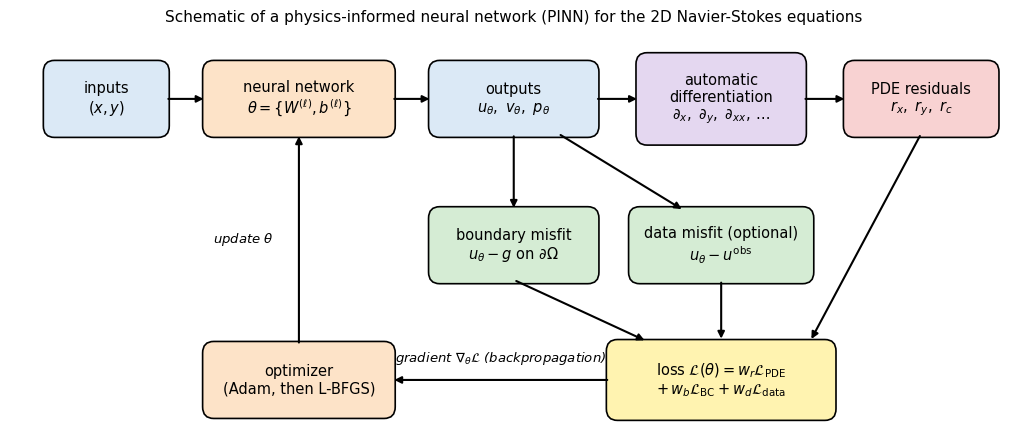

In [190]:
def draw_text_box(ax, center, text, color, width=2.2, height=0.9):
    """Draw a rounded box with centered text; center = (x, y) in data coordinates."""
    x, y = center
    ax.add_patch(FancyBboxPatch((x - width / 2, y - height / 2), width, height,
                                boxstyle="round,pad=0.05,rounding_size=0.15",
                                facecolor=color, edgecolor="black", linewidth=1.2))
    ax.text(x, y, text, ha="center", va="center", fontsize=10.5)


def draw_arrow(ax, start, end, text=None, offset=(0.0, 0.18)):
    """Draw an arrow from start to end, optionally labelled near its midpoint."""
    ax.annotate("", xy=end, xytext=start, arrowprops=dict(arrowstyle="-|>", lw=1.5, color="black"))
    if text is not None:
        ax.text((start[0] + end[0]) / 2 + offset[0], (start[1] + end[1]) / 2 + offset[1], text,
                ha="center", va="bottom", fontsize=9.5, style="italic")


fig, ax = plt.subplots(figsize=(13, 5.2))
ax.set_xlim(-0.3, 13.3); ax.set_ylim(-0.1, 5.1); ax.axis("off")
# Top row: inputs -> network -> outputs -> AD -> residuals
draw_text_box(ax, (1.0, 4.2), "inputs\n$(x, y)$", "#dbe9f6", width=1.6)
draw_text_box(ax, (3.6, 4.2), "neural network\n$\\theta = \\{W^{(\\ell)}, b^{(\\ell)}\\}$", "#fde3c8", width=2.5)
draw_text_box(ax, (6.5, 4.2), "outputs\n$u_\\theta,\\ v_\\theta,\\ p_\\theta$", "#dbe9f6")
draw_text_box(ax, (9.3, 4.2), "automatic\ndifferentiation\n$\\partial_x,\\ \\partial_y,\\ \\partial_{xx}, \\dots$", "#e4d7f0", height=1.1)
draw_text_box(ax, (12.0, 4.2), "PDE residuals\n$r_x,\\ r_y,\\ r_c$", "#f8d2d2", width=2.0)
for x0, x1 in [(1.8, 2.35), (4.85, 5.4), (7.6, 8.2), (10.4, 11.0)]:
    draw_arrow(ax, (x0, 4.2), (x1, 4.2))
# Middle row: boundary and data misfits
draw_text_box(ax, (6.5, 2.3), "boundary misfit\n$u_\\theta - g$ on $\\partial\\Omega$", "#d5ecd4")
draw_text_box(ax, (9.3, 2.3), "data misfit (optional)\n$u_\\theta - u^{\\mathrm{obs}}$", "#d5ecd4", width=2.4)
draw_arrow(ax, (6.5, 3.75), (6.5, 2.75)); draw_arrow(ax, (7.1, 3.75), (8.8, 2.75))
# Bottom row: loss and optimizer
draw_text_box(ax, (9.3, 0.55), "loss $\\mathcal{L}(\\theta) = w_r\\mathcal{L}_{\\mathrm{PDE}}$\n$+\\, w_b\\mathcal{L}_{\\mathrm{BC}} + w_d\\mathcal{L}_{\\mathrm{data}}$", "#fff3b0", width=3.0, height=0.95)
draw_text_box(ax, (3.6, 0.55), "optimizer\n(Adam, then L-BFGS)", "#fde3c8", width=2.5)
draw_arrow(ax, (12.0, 3.75), (10.5, 1.05)); draw_arrow(ax, (6.5, 1.85), (8.3, 1.05))
draw_arrow(ax, (9.3, 1.85), (9.3, 1.05))
draw_arrow(ax, (7.8, 0.55), (4.85, 0.55), text="gradient $\\nabla_\\theta \\mathcal{L}$ (backpropagation)")
draw_arrow(ax, (3.6, 1.0), (3.6, 3.75), text="update $\\theta$", offset=(-0.75, -0.1))
ax.set_title("Schematic of a physics-informed neural network (PINN) for the 2D Navier-Stokes equations")
plt.show()

## 3.2 The incompressible Navier-Stokes equations

The velocity $\mathbf{u}(\mathbf{x},t)$ and pressure $p(\mathbf{x},t)$ of an incompressible Newtonian fluid with constant density satisfy the **incompressible Navier-Stokes equations**

$$
\begin{aligned}
\frac{\partial \mathbf{u}}{\partial t} + (\mathbf{u}\cdot\nabla)\mathbf{u} &= -\nabla p + \nu\,\Delta\mathbf{u} + \mathbf{f} && \text{(momentum)}, \\
\nabla\cdot\mathbf{u} &= 0 && \text{(incompressibility)}.
\end{aligned}
$$

| Term | Meaning |
|:--|:--|
| $\partial_t\mathbf{u}$ | local acceleration |
| $(\mathbf{u}\cdot\nabla)\mathbf{u}$ | convection, the **nonlinear** term |
| $-\nabla p$ | pressure force ($p$ = pressure / constant density) |
| $\nu\,\Delta\mathbf{u}$ | viscous diffusion; $\nu > 0$ is the kinematic viscosity |
| $\mathbf{f}$ | body force (here $\mathbf{f} = \mathbf{0}$) |
| $\nabla\cdot\mathbf{u} = 0$ | mass conservation |

There is no evolution equation for $p$: the pressure acts as a Lagrange multiplier that enforces $\nabla\cdot\mathbf{u} = 0$.

**Reynolds number.** In nondimensional variables $\nu$ is replaced by $1/Re$, where $Re = UL/\nu$ (characteristic speed $U$, length $L$) measures inertial against viscous effects. Small $Re$ means smooth laminar flow; large $Re$ means thin layers and eventually turbulence.

**Steady 2D equations.** For $\partial_t\mathbf{u} = 0$, $\mathbf{f} = \mathbf{0}$ and $\mathbf{u} = (u, v)$ depending on $(x, y)$:

$$
\begin{aligned}
u\,u_x + v\,u_y &= -p_x + \nu\,(u_{xx} + u_{yy}), \\
u\,v_x + v\,v_y &= -p_y + \nu\,(v_{xx} + v_{yy}), \\
u_x + v_y &= 0 ,
\end{aligned}
$$

where subscripts denote partial derivatives: three equations for $u, v, p$.

> **Pitfall.** The pressure appears only through $\nabla p$. If the velocity is prescribed on the *whole* boundary, then $(\mathbf{u}, p + c)$ is a solution for every constant $c$: **the pressure is determined only up to an additive constant**, which a solver must fix (e.g. by prescribing $p$ at a point or on part of the boundary).

**Benchmark: Kovasznay flow.** To check a method we need an exact solution. Kovasznay (1948) found one for the steady 2D equations, modelling the laminar flow behind a two-dimensional grid of bars; it is a standard PINN benchmark, e.g. in NSFnets (Jin et al., 2021). With $\nu = 1/Re$ and

$$
\lambda = \frac{Re}{2} - \sqrt{\frac{Re^2}{4} + 4\pi^2} \quad (< 0),
$$

$$
\begin{aligned}
u(x,y) &= 1 - e^{\lambda x}\cos(2\pi y), \\
v(x,y) &= \frac{\lambda}{2\pi}\, e^{\lambda x}\sin(2\pi y), \\
p(x,y) &= \frac{1}{2}\left(1 - e^{2\lambda x}\right).
\end{aligned}
$$

We use $\Omega = [-0.5, 1]\times[-0.5, 1.5]$ and $Re = 20$, so $\nu = 0.05$ and $\lambda \approx -1.81$.

> **Try it.** Check by hand that $u_x + v_y = 0$; the momentum equations are checked with autograd in Section 3.5.

The next cell defines the parameters and the exact solution; passing the array library (`np` or `torch`) lets one formula serve for plotting and for training data. The cell after it plots the speed $|\mathbf{u}| = \sqrt{u^2 + v^2}$ with streamlines (curves tangent to the velocity) and the pressure.

In [191]:
RE = 20.0                                              # Reynolds number
NU = 1.0 / RE                                          # nondimensional viscosity nu = 1/Re
LAM = RE / 2 - math.sqrt(RE**2 / 4 + 4 * math.pi**2)   # lambda in Kovasznay's solution
X_MIN, X_MAX = -0.5, 1.0                               # domain [X_MIN, X_MAX] x [Y_MIN, Y_MAX]
Y_MIN, Y_MAX = -0.5, 1.5


def kovasznay(x, y, lib=np):
    """Exact Kovasznay flow.

    Args:
        x, y: NumPy arrays (lib=np) or PyTorch tensors (lib=torch) of the same shape.
        lib: the array library, np or torch.
    Returns:
        u, v, p: arrays/tensors of the same shape as x.
    """
    e = lib.exp(LAM * x)
    u = 1.0 - e * lib.cos(2 * math.pi * y)
    v = LAM / (2 * math.pi) * e * lib.sin(2 * math.pi * y)
    p = 0.5 * (1.0 - lib.exp(2 * LAM * x))
    return u, v, p


# Regular grid for plots and errors. np.meshgrid (default indexing="xy") gives shape (ny, nx).
xs = np.linspace(X_MIN, X_MAX, 151)
ys = np.linspace(Y_MIN, Y_MAX, 201)
X, Y = np.meshgrid(xs, ys)                             # shape (201, 151): rows = y, columns = x
U_ex, V_ex, P_ex = kovasznay(X, Y)
print(f"lambda = {LAM:.4f}, grid shape = {X.shape}")

lambda = -1.8101, grid shape = (201, 151)


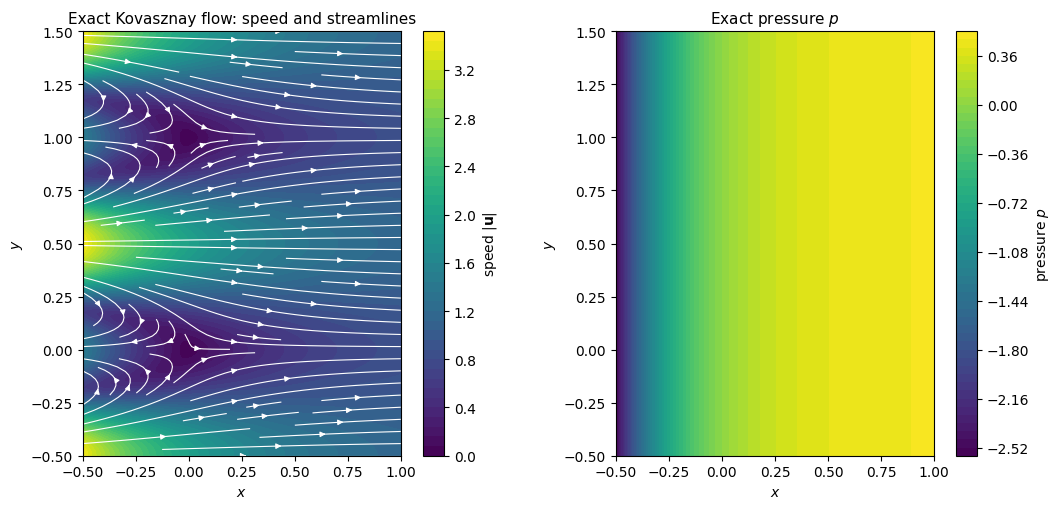

In [192]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
cf = axes[0].contourf(X, Y, np.sqrt(U_ex**2 + V_ex**2), levels=50, cmap="viridis")
axes[0].streamplot(xs, ys, U_ex, V_ex, color="white", density=1.2, linewidth=0.8, arrowsize=0.8)
fig.colorbar(cf, ax=axes[0], label=r"speed $|\mathbf{u}|$")
axes[0].set_title("Exact Kovasznay flow: speed and streamlines")
cf = axes[1].contourf(X, Y, P_ex, levels=50, cmap="viridis")
fig.colorbar(cf, ax=axes[1], label="pressure $p$")
axes[1].set_title("Exact pressure $p$")
for ax in axes:
    ax.set_xlabel("$x$"); ax.set_ylabel("$y$")
    ax.set_aspect("equal"); ax.set_xlim(X_MIN, X_MAX); ax.set_ylim(Y_MIN, Y_MAX)
plt.tight_layout()
plt.show()

**Observe.** The mean flow goes from left to right. Near the left boundary fast jets alternate with slow wakes around $y = 0$ and $y = 1$, where the flow even reverses ($u < 0$). The pattern is periodic in $y$ and decays like $e^{\lambda x}$, so downstream the flow approaches $\mathbf{u} = (1, 0)$. The pressure depends only on $x$ and increases from left to right.

## 3.3 The PINN formulation for Navier-Stokes

**Network and residuals.** One network maps the two coordinates to the three unknowns, $(x, y) \mapsto (u_\theta, v_\theta, p_\theta)$. Moving all terms of the steady equations to the left-hand side defines three residuals:

$$
\begin{aligned}
r_x &= u_\theta\,\partial_x u_\theta + v_\theta\,\partial_y u_\theta + \partial_x p_\theta - \nu\left(\partial_{xx} u_\theta + \partial_{yy} u_\theta\right), \\
r_y &= u_\theta\,\partial_x v_\theta + v_\theta\,\partial_y v_\theta + \partial_y p_\theta - \nu\left(\partial_{xx} v_\theta + \partial_{yy} v_\theta\right), \\
r_c &= \partial_x u_\theta + \partial_y v_\theta .
\end{aligned}
$$

**Training points and loss.** We use $N_r$ interior collocation points $\mathbf{x}_i^r$, $N_b$ points $\mathbf{x}_j^b$ on all four sides with the exact velocity $(u_j^b, v_j^b)$, and $N_p$ outlet points $\mathbf{x}_k^p$ on the right side $x = 1$ with the exact pressure $p_k^p$, which fixes the pressure constant:

$$
\begin{aligned}
\mathcal{L}(\theta) &= w_r\,\mathcal{L}_{\mathrm{PDE}} + w_b\,\mathcal{L}_{\mathrm{BC}} + w_p\,\mathcal{L}_{p}, \qquad
\mathcal{L}_{\mathrm{PDE}} = \frac{1}{N_r}\sum_{i=1}^{N_r}\big(r_x^2 + r_y^2 + r_c^2\big)(\mathbf{x}_i^r), \\
\mathcal{L}_{\mathrm{BC}} &= \frac{1}{N_b}\sum_{j=1}^{N_b}\Big(\big(u_\theta(\mathbf{x}_j^b) - u_j^b\big)^2 + \big(v_\theta(\mathbf{x}_j^b) - v_j^b\big)^2\Big), \qquad
\mathcal{L}_{p} = \frac{1}{N_p}\sum_{k=1}^{N_p}\big(p_\theta(\mathbf{x}_k^p) - p_k^p\big)^2 .
\end{aligned}
$$

Without the boundary terms the residual has infinitely many minimizers; weighting them more ($w_r = 1$, $w_b = w_p = 10$, a heuristic choice found by trial) helps the optimizer enforce them early.

**Training recipe.** First **Adam** (Kingma and Ba, 2015), robust from a random start but slow near a minimum; then **L-BFGS**, a quasi-Newton method with line search that is much faster near a minimum.

> **Remark (activation).** The residual contains **second derivatives** of the network. A ReLU network is piecewise linear, so its second derivative is zero almost everywhere and the viscous term $\nu\Delta u_\theta$ would vanish. Use smooth activations such as $\tanh$.

> **Remark (input normalization).** Networks train best with inputs of order one. We map the domain affinely to $[-1, 1]^2$ *inside* the network, so autograd still differentiates with respect to the physical $x, y$.

## 3.4 PyTorch essentials

PyTorch (Paszke et al., 2019) provides **tensors** (NumPy-like arrays with a shape, a dtype and a device; the default dtype is float32, NumPy's is float64), **automatic differentiation** and building blocks for **networks and optimizers**.

A tensor with `requires_grad=True` records every operation applied to it. For PINNs we need derivatives **at many points at once** and **of higher order**: `torch.autograd.grad(outputs, inputs, grad_outputs=..., create_graph=True)` returns the derivative, and `create_graph=True` records this computation too, so that we can differentiate again (for $u_{xx}$) and backpropagate through it during training. The next cell verifies $\frac{d}{dx}\sin x = \cos x$ and $\frac{d^2}{dx^2}\sin x = -\sin x$ on 101 points.

In [193]:
x = torch.linspace(0.0, 2 * math.pi, 101).reshape(-1, 1)   # tensor of shape (101, 1): one point per row
print("shape:", tuple(x.shape), "| dtype:", x.dtype, "| device:", x.device)
x.requires_grad_(True)                                      # record operations on x
y = torch.sin(x)                                            # shape (101, 1)

# First derivative at every point, shape (101, 1); create_graph=True allows differentiating again
dy_dx = torch.autograd.grad(y, x, grad_outputs=torch.ones_like(y), create_graph=True)[0]
d2y_dx2 = torch.autograd.grad(dy_dx, x, grad_outputs=torch.ones_like(dy_dx), create_graph=True)[0]

print(f"max |dy/dx   - cos x| = {(dy_dx - torch.cos(x)).abs().max().item():.2e}")
print(f"max |d2y/dx2 + sin x| = {(d2y_dx2 + torch.sin(x)).abs().max().item():.2e}")

shape: (101, 1) | dtype: torch.float32 | device: cpu
max |dy/dx   - cos x| = 0.00e+00
max |d2y/dx2 + sin x| = 0.00e+00


**Observe.** Both errors are zero or at the level of float32 round-off (about $10^{-7}$): autograd applies exact derivative rules.

<details><summary>Why <code>grad_outputs = ones</code>?</summary>

For outputs $\mathbf{y}\in\mathbb{R}^N$ and inputs $\mathbf{x}\in\mathbb{R}^N$, `torch.autograd.grad` returns the vector-Jacobian product $\mathbf{w}^\top J$ with $J_{ik} = \partial y_i/\partial x_k$ and $\mathbf{w}$ = `grad_outputs`. Here $y_i$ depends only on $x_i$, so $J$ is diagonal and $\mathbf{w} = (1,\dots,1)$ returns exactly the pointwise derivatives $\partial y_i/\partial x_i$. The same holds for a network applied to a batch of points, since each row is processed independently.

</details>

**Networks as `nn.Module`.** A PyTorch network is a class derived from `nn.Module`: `__init__` creates the layers and `forward` evaluates the formula of Section 3.1; `nn.Linear(n_in, n_out)` maps each row $\mathbf{z}$ to $W\mathbf{z} + \mathbf{b}$. **Xavier initialization** scales the random weights by the layer sizes so that signals neither explode nor vanish, the standard choice for $\tanh$ networks.

In [194]:
class MLP(nn.Module):
    """Fully connected feed-forward network with tanh activations.

    Args:
        layer_sizes: [n_0, n_1, ..., n_L] = input size, hidden widths, output size, e.g. [2, 50, 50, 3].
    Input/output: tensor of shape (N, n_0) -> tensor of shape (N, n_L).
    """

    def __init__(self, layer_sizes):
        super().__init__()
        layers = []
        for n_in, n_out in zip(layer_sizes[:-2], layer_sizes[1:-1]):
            layers += [nn.Linear(n_in, n_out), nn.Tanh()]              # sigma(W z + b)
        layers.append(nn.Linear(layer_sizes[-2], layer_sizes[-1]))     # linear output layer
        self.layers = nn.Sequential(*layers)
        for module in self.layers:                                     # Xavier weights, zero biases
            if isinstance(module, nn.Linear):
                nn.init.xavier_normal_(module.weight)
                nn.init.zeros_(module.bias)

    def forward(self, z):
        """Evaluate the network on a batch z of shape (N, n_0)."""
        return self.layers(z)

**The training loop.** Every PyTorch training loop follows the same five steps:

```python
optimizer.zero_grad()      # 1. reset the gradients of the previous step
prediction = model(x)      # 2. forward pass
loss = loss_fn(prediction) # 3. scalar loss
loss.backward()            # 4. backpropagation: d(loss)/d(theta) -> .grad of every parameter
optimizer.step()           # 5. update the parameters
```

> **Pitfall.** Without `optimizer.zero_grad()` PyTorch *adds* the new gradient to the old one, which silently ruins training.

## 3.5 Implementing the PINN

We now solve the **forward problem**: given $\nu$, the boundary velocity and the outlet pressure, find $(u, v, p)$. The exact solution only generates these data and measures the error.

The device and the precision were chosen in the setup of Part 3; the next cell collects all training hyperparameters in the dictionary `CONFIG`.

In [195]:
torch.manual_seed(1234)                              # seeds the random points of the autograd check below

CONFIG = {
    "layers": [2, 50, 50, 50, 50, 3],  # (x, y) -> 4 hidden tanh layers of width 50 -> (u, v, p)
    "n_interior": 1000,                # N_r: interior collocation points
    "n_boundary_per_side": 100,        # boundary points per side (N_b = 400)
    "n_adam": 2000,                    # number of Adam iterations
    "lr_adam": 3e-3,                   # initial Adam learning rate ...
    "lr_adam_final": 3e-4,             # ... decayed exponentially to this value
    "n_lbfgs": 2000,                   # maximum number of L-BFGS iterations
    "w_pde": 1.0, "w_bc": 10.0, "w_p": 10.0,   # loss weights w_r, w_b, w_p
}
# Slow laptop? Halve n_adam and n_lbfgs: training is about twice as fast, and the
# errors roughly double (in our tests they stayed below 0.5%).

**Residuals and an autograd check.** The next cell defines `gradient` (the pointwise derivative of Section 3.4) and the residual function. The latter takes the fields $u, v, p$ rather than a network, so it applies to the exact solution and to the PINN alike. The cell after it **tests the residual code**: the exact solution (1000 random points, float64) must give zero up to round-off. Make such tests a habit.

In [196]:
def gradient(y, x):
    """Pointwise derivative dy/dx for a batch of points.

    Args:
        y: tensor of shape (N, 1) computed from x; x: tensor of shape (N, 1) with requires_grad=True.
    Returns:
        Tensor of shape (N, 1); the graph is kept so the result can be differentiated again.
    """
    dy_dx = torch.autograd.grad(y, x, grad_outputs=torch.ones_like(y),
                                create_graph=True, allow_unused=True)[0]
    return torch.zeros_like(x) if dy_dx is None else dy_dx   # None: y does not depend on x


def navier_stokes_residuals(u, v, p, x, y, nu):
    """Residuals r_x, r_y, r_c (each of shape (N, 1)) of the steady 2D Navier-Stokes equations.

    Args:
        u, v, p: tensors of shape (N, 1) computed from x, y (shape (N, 1), requires_grad=True).
        nu: viscosity (float, or a tensor if nu is learned in an inverse problem).
    """
    u_x, u_y = gradient(u, x), gradient(u, y)
    v_x, v_y = gradient(v, x), gradient(v, y)
    p_x, p_y = gradient(p, x), gradient(p, y)
    u_xx, u_yy = gradient(u_x, x), gradient(u_y, y)
    v_xx, v_yy = gradient(v_x, x), gradient(v_y, y)
    r_x = u * u_x + v * u_y + p_x - nu * (u_xx + u_yy)
    r_y = u * v_x + v * v_y + p_y - nu * (v_xx + v_yy)
    r_c = u_x + v_y
    return r_x, r_y, r_c

In [197]:
x_chk = (X_MIN + (X_MAX - X_MIN) * torch.rand(1000, 1, dtype=torch.float64)).requires_grad_(True)
y_chk = (Y_MIN + (Y_MAX - Y_MIN) * torch.rand(1000, 1, dtype=torch.float64)).requires_grad_(True)
u_chk, v_chk, p_chk = kovasznay(x_chk, y_chk, lib=torch)
residuals_chk = navier_stokes_residuals(u_chk, v_chk, p_chk, x_chk, y_chk, NU)
for name, r in zip(["r_x", "r_y", "r_c"], residuals_chk):
    print(f"max |{name}| for the exact solution: {r.abs().max().item():.2e}")

max |r_x| for the exact solution: 4.44e-15
max |r_y| for the exact solution: 8.88e-16
max |r_c| for the exact solution: 8.88e-16


**Observe.** All three residuals are at the level of float64 round-off, so the exact solution and the residual code are consistent; a sign error would give residuals of order one. (`gradient` uses `allow_unused=True` because the exact $p$ does not depend on $y$; $\partial_y p$ then comes out as zero.)

**Training points.** Interior points are uniformly random; random points on each side carry the exact velocity, and those on the right side $x = 1$ also carry the exact outlet pressure. Points are column tensors of shape `(N, 1)`; the interior ones get `requires_grad=True` because we differentiate with respect to them. The second cell plots them.

In [198]:
gen = torch.Generator().manual_seed(0)                 # own generator: reproducible points
n_r, n_side = CONFIG["n_interior"], CONFIG["n_boundary_per_side"]


def uniform(n, lo, hi):
    """n samples from the uniform distribution on [lo, hi), as a tensor of shape (n, 1)."""
    return lo + (hi - lo) * torch.rand(n, 1, generator=gen, dtype=DTYPE)


x_r, y_r = uniform(n_r, X_MIN, X_MAX), uniform(n_r, Y_MIN, Y_MAX)   # interior, shape (N_r, 1)
ones = torch.ones(n_side, 1, dtype=DTYPE)                           # sides: left, right, bottom, top
x_b = torch.cat([X_MIN * ones, X_MAX * ones, uniform(n_side, X_MIN, X_MAX), uniform(n_side, X_MIN, X_MAX)])
y_b = torch.cat([uniform(n_side, Y_MIN, Y_MAX), uniform(n_side, Y_MIN, Y_MAX), Y_MIN * ones, Y_MAX * ones])
u_b, v_b, _ = kovasznay(x_b, y_b, lib=torch)                        # Dirichlet velocity data
x_p, y_p = x_b[n_side:2 * n_side], y_b[n_side:2 * n_side]           # outlet = right side x = X_MAX
p_p = kovasznay(x_p, y_p, lib=torch)[2]                             # exact outlet pressure

x_r, y_r = x_r.to(DEVICE).requires_grad_(True), y_r.to(DEVICE).requires_grad_(True)
x_b, y_b, u_b, v_b, x_p, y_p, p_p = (t.to(DEVICE) for t in (x_b, y_b, u_b, v_b, x_p, y_p, p_p))
print(f"N_r = {x_r.shape[0]}, N_b = {x_b.shape[0]}, N_p = {x_p.shape[0]}")

N_r = 1000, N_b = 400, N_p = 100


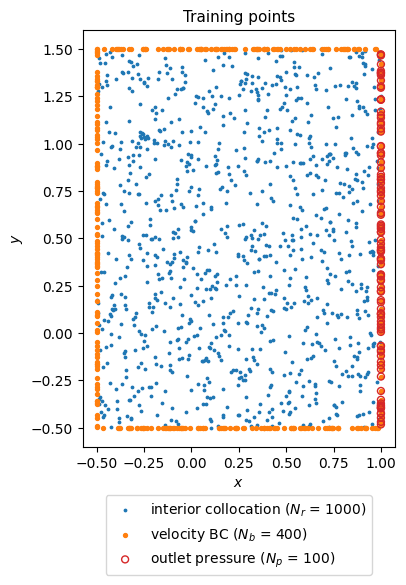

In [199]:
fig, ax = plt.subplots(figsize=(5, 6))
ax.scatter(x_r.detach().cpu().numpy(), y_r.detach().cpu().numpy(), s=3, c="C0", label=f"interior collocation ($N_r$ = {n_r})")
ax.scatter(x_b.cpu().numpy(), y_b.cpu().numpy(), s=8, c="C1", label=f"velocity BC ($N_b$ = {x_b.shape[0]})")
ax.scatter(x_p.cpu().numpy(), y_p.cpu().numpy(), s=25, facecolors="none", edgecolors="C3",
           label=f"outlet pressure ($N_p$ = {x_p.shape[0]})")
ax.set_xlabel("$x$"); ax.set_ylabel("$y$"); ax.set_aspect("equal")
ax.set_title("Training points")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.tight_layout()
plt.show()

**The network and the loss.** The PINN wraps the `MLP` of Section 3.4. Its `forward` takes `x` and `y` as **separate** column tensors (so that we can differentiate with respect to each), applies the input normalization of Section 3.3 and splits the three outputs. The loss function after it implements the formula of Section 3.3 and also returns the three components for monitoring.

In [200]:
class NavierStokesPINN(nn.Module):
    """PINN for steady 2D incompressible flow: (x, y) -> (u, v, p).

    Args:
        layer_sizes: layer widths, starting with 2 and ending with 3.
        lower, upper: (x_min, y_min) and (x_max, y_max); inputs are mapped affinely to [-1, 1]^2.
    """

    def __init__(self, layer_sizes, lower, upper):
        super().__init__()
        self.mlp = MLP(layer_sizes)
        # buffers are saved and moved with the model (.to), but not trained
        self.register_buffer("lower", torch.tensor(lower, dtype=torch.float32))
        self.register_buffer("upper", torch.tensor(upper, dtype=torch.float32))

    def forward(self, x, y):
        """x, y: tensors of shape (N, 1). Returns u, v, p, each of shape (N, 1)."""
        xy = torch.cat([x, y], dim=1)                                     # (N, 2)
        out = self.mlp(2.0 * (xy - self.lower) / (self.upper - self.lower) - 1.0)   # (N, 3)
        return out[:, 0:1], out[:, 1:2], out[:, 2:3]


torch.manual_seed(1234)
pinn = NavierStokesPINN(CONFIG["layers"], lower=(X_MIN, Y_MIN), upper=(X_MAX, Y_MAX)).to(DEVICE, DTYPE)
print(f"trainable parameters: {sum(p.numel() for p in pinn.parameters())}")

trainable parameters: 7953


In [201]:
def pinn_loss(model, nu=NU):
    """PINN loss for the Kovasznay forward problem (uses the global training points and CONFIG).

    Returns:
        total: scalar tensor w_pde * L_PDE + w_bc * L_BC + w_p * L_p.
        parts: dict with the float values of L_PDE, L_BC, L_p.
    """
    u, v, p = model(x_r, y_r)                                          # PDE residual (interior)
    r_x, r_y, r_c = navier_stokes_residuals(u, v, p, x_r, y_r, nu)
    loss_pde = torch.mean(r_x**2) + torch.mean(r_y**2) + torch.mean(r_c**2)
    u_pred, v_pred, _ = model(x_b, y_b)                                # velocity on the 4 sides
    loss_bc = torch.mean((u_pred - u_b) ** 2) + torch.mean((v_pred - v_b) ** 2)
    _, _, p_pred = model(x_p, y_p)                                     # outlet pressure
    loss_p = torch.mean((p_pred - p_p) ** 2)
    total = CONFIG["w_pde"] * loss_pde + CONFIG["w_bc"] * loss_bc + CONFIG["w_p"] * loss_p
    return total, {"pde": loss_pde.item(), "bc": loss_bc.item(), "p": loss_p.item()}


total0, parts0 = pinn_loss(pinn)
print(f"loss of the untrained network: {total0.item():.3e} ("
      + ", ".join(f"{k} = {v:.2e}" for k, v in parts0.items()) + ")")

loss of the untrained network: 3.596e+01 (pde = 1.31e-01, bc = 3.46e+00, p = 1.23e-01)


## 3.6 Training

These are the longest-running cells of the notebook; start them and read the explanation below while they run.

**Phase 1: Adam.** The learning rate decays exponentially from `lr_adam` to `lr_adam_final`. We store the loss components in `history` and print a short log.

**Phase 2: L-BFGS.** `torch.optim.LBFGS` needs a **closure**, a function that recomputes the loss and its gradient, because the line search evaluates the loss several times per iteration. A single call `optimizer.step(closure)` runs up to `max_iter` iterations; the strong Wolfe line search makes L-BFGS robust. Here `history` records every loss evaluation; their number can exceed `max_iter`, because one iteration may need several evaluations (PyTorch caps them at `max_eval` = 1.25 `max_iter` by default).

In [202]:
history = {"total": [], "pde": [], "bc": [], "p": []}


def record(total, parts):
    """Append the current loss values to the global history."""
    history["total"].append(total.item())
    for key, value in parts.items():
        history[key].append(value)


optimizer = torch.optim.Adam(pinn.parameters(), lr=CONFIG["lr_adam"])
lr_decay = (CONFIG["lr_adam_final"] / CONFIG["lr_adam"]) ** (1.0 / CONFIG["n_adam"])
scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=lr_decay)   # lr <- lr_decay * lr

t_start = time.perf_counter()
for it in range(1, CONFIG["n_adam"] + 1):
    optimizer.zero_grad()                       # the five steps of Section 3.4
    total, parts = pinn_loss(pinn)
    total.backward()
    optimizer.step()
    scheduler.step()
    record(total, parts)
    if it == 1 or it % 500 == 0:
        print(f"Adam {it:5d} | loss {total.item():.3e} | pde {parts['pde']:.2e} "
              f"bc {parts['bc']:.2e} p {parts['p']:.2e} | {time.perf_counter() - t_start:5.1f} s")
n_adam_done = len(history["total"])

Adam     1 | loss 3.596e+01 | pde 1.31e-01 bc 3.46e+00 p 1.23e-01 |   0.0 s
Adam   500 | loss 3.151e-01 | pde 1.40e-01 bc 1.74e-02 p 8.58e-05 |   7.4 s
Adam  1000 | loss 7.539e-02 | pde 5.04e-02 bc 2.46e-03 p 3.92e-05 |  14.7 s
Adam  1500 | loss 4.863e-02 | pde 3.39e-02 bc 1.44e-03 p 3.80e-05 |  22.5 s
Adam  2000 | loss 3.859e-02 | pde 2.70e-02 bc 1.12e-03 p 3.71e-05 |  30.0 s


In [203]:
optimizer = torch.optim.LBFGS(pinn.parameters(), lr=1.0,       # lr = 1 is standard with a line search
                              max_iter=CONFIG["n_lbfgs"],      # maximum iterations in this call
                              history_size=50,                 # stored pairs for the Hessian approximation
                              tolerance_grad=1e-9, tolerance_change=1e-12,
                              line_search_fn="strong_wolfe")


def closure():
    """Recompute loss and gradients (called repeatedly by L-BFGS)."""
    optimizer.zero_grad()
    total, parts = pinn_loss(pinn)
    total.backward()
    record(total, parts)
    if (len(history["total"]) - n_adam_done) % 500 == 0:
        print(f"L-BFGS eval {len(history['total']) - n_adam_done:5d} | loss {total.item():.3e} "
              f"| {time.perf_counter() - t_start:5.1f} s")
    return total


optimizer.step(closure)
time_total = time.perf_counter() - t_start
print(f"L-BFGS: {len(history['total']) - n_adam_done} loss evaluations, final loss {history['total'][-1]:.3e}")
print(f"wall-clock time for the whole training: {time_total:.1f} s")

L-BFGS eval   500 | loss 9.182e-04 |  37.6 s
L-BFGS eval  1000 | loss 2.594e-04 |  45.6 s
L-BFGS eval  1500 | loss 1.244e-04 |  53.4 s
L-BFGS eval  2000 | loss 6.612e-05 |  61.0 s
L-BFGS: 2152 loss evaluations, final loss 5.690e-05
wall-clock time for the whole training: 63.3 s


## 3.7 Results and visualization

**Loss history.** Total loss and components on a logarithmic scale; the dashed line marks the switch from Adam to L-BFGS.

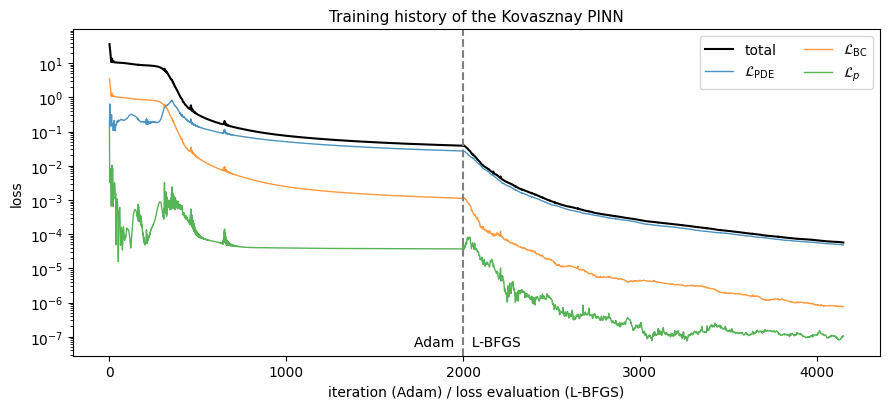

In [204]:
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.semilogy(history["total"], "k", lw=1.5, label="total")
ax.semilogy(history["pde"], lw=1, alpha=0.8, label=r"$\mathcal{L}_{\mathrm{PDE}}$")
ax.semilogy(history["bc"], lw=1, alpha=0.8, label=r"$\mathcal{L}_{\mathrm{BC}}$")
ax.semilogy(history["p"], lw=1, alpha=0.8, label=r"$\mathcal{L}_{p}$")
ax.axvline(n_adam_done, color="gray", ls="--")
ax.text(n_adam_done, 0.03, "Adam  ", transform=ax.get_xaxis_transform(), ha="right")
ax.text(n_adam_done, 0.03, "  L-BFGS", transform=ax.get_xaxis_transform(), ha="left")
ax.set_xlabel("iteration (Adam) / loss evaluation (L-BFGS)"); ax.set_ylabel("loss")
ax.set_title("Training history of the Kovasznay PINN")
ax.legend(loc="upper right", ncol=2)
plt.tight_layout()
plt.show()

**Observe.** During Adam the loss drops quickly at first and then only slowly, with occasional spikes. L-BFGS then reduces it smoothly by two to three orders of magnitude. At the end $\mathcal{L}_{\mathrm{PDE}}$ dominates the total loss.

**Errors on a grid.** We evaluate the trained network on the grid of Section 3.2 (inside `torch.no_grad()`, since no derivatives are needed) and compute the relative $L^2$ errors $\|u_\theta - u\|_2/\|u\|_2$. The next figure shows exact solution, PINN and pointwise error for each field; in each row, exact solution and PINN share the color scale.

In [205]:
def evaluate_on_grid(model, X, Y):
    """Evaluate a (x, y) -> (u, v, p) model on a meshgrid; X, Y and the results have shape (ny, nx)."""
    x = torch.tensor(X.reshape(-1, 1), dtype=DTYPE, device=DEVICE)
    y = torch.tensor(Y.reshape(-1, 1), dtype=DTYPE, device=DEVICE)
    with torch.no_grad():
        u, v, p = model(x, y)
    return tuple(t.cpu().numpy().reshape(X.shape) for t in (u, v, p))


def relative_l2(pred, exact):
    """Discrete relative L2 error ||pred - exact|| / ||exact|| over all grid points."""
    return np.linalg.norm(pred - exact) / np.linalg.norm(exact)


U_pinn, V_pinn, P_pinn = evaluate_on_grid(pinn, X, Y)
errors = {"u": relative_l2(U_pinn, U_ex), "v": relative_l2(V_pinn, V_ex), "p": relative_l2(P_pinn, P_ex)}
print(f"Relative L2 errors on the {X.shape[1]} x {X.shape[0]} grid:  "
      + ",  ".join(f"{k}: {v:.2e}" for k, v in errors.items()))

Relative L2 errors on the 151 x 201 grid:  u: 5.83e-04,  v: 1.93e-03,  p: 1.28e-03


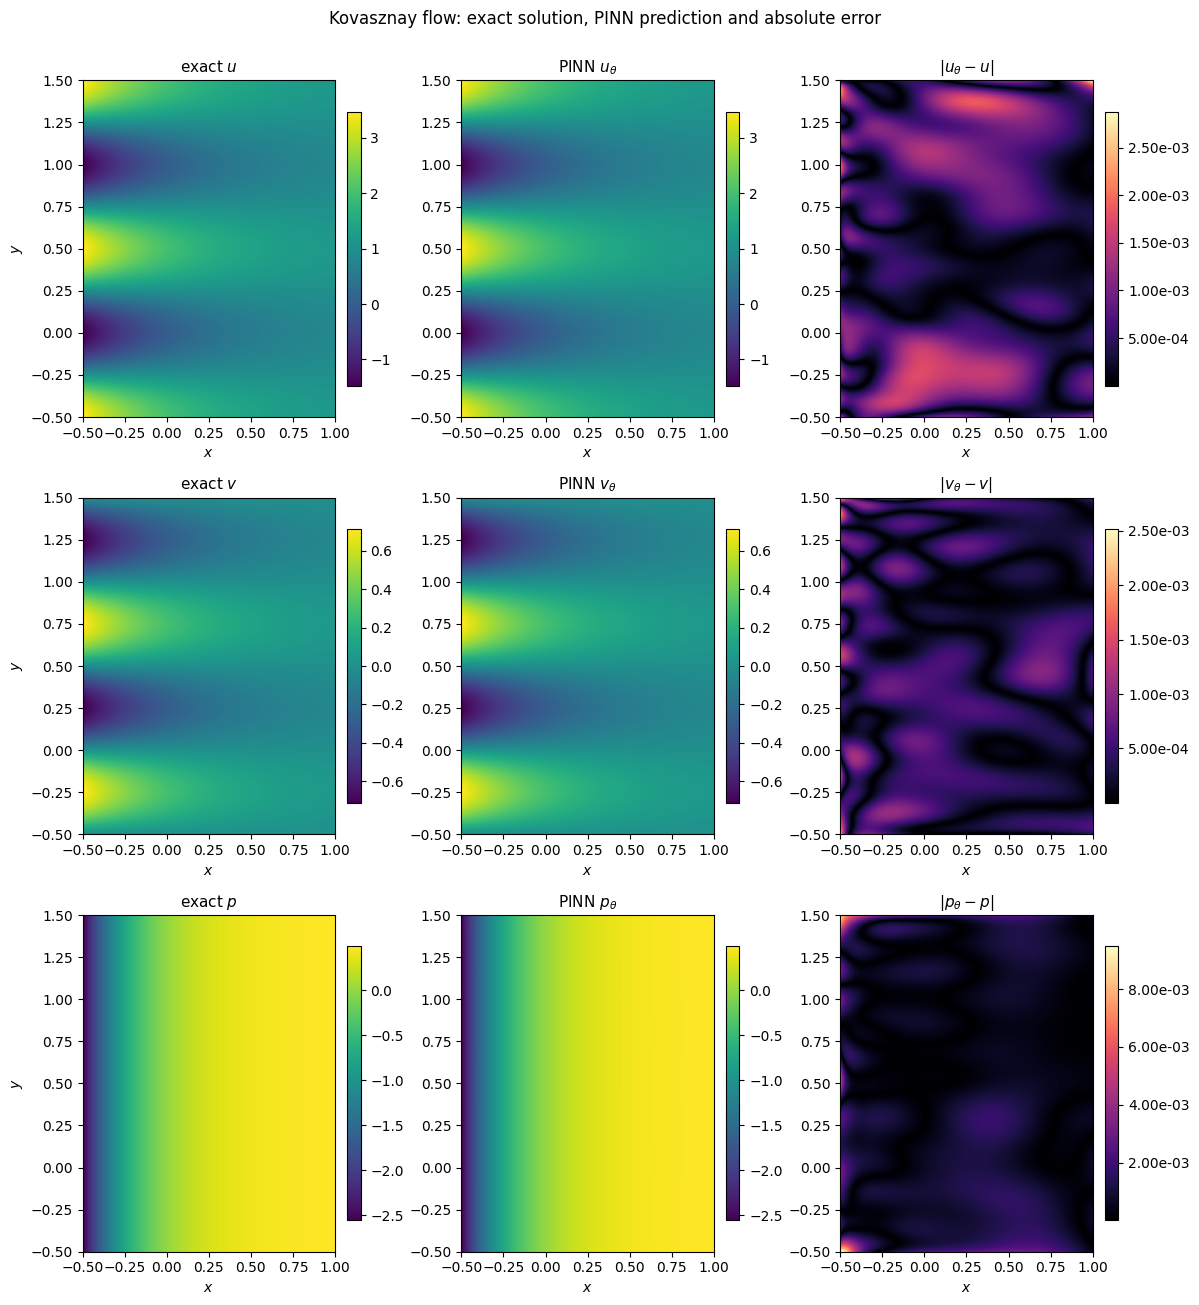

In [206]:
fig, axes = plt.subplots(3, 3, figsize=(12, 13))
for row, (name, exact, pred) in enumerate([("u", U_ex, U_pinn), ("v", V_ex, V_pinn), ("p", P_ex, P_pinn)]):
    vmin, vmax = exact.min(), exact.max()          # shared color limits for exact and PINN
    panels = [(exact, f"exact ${name}$", "viridis", vmin, vmax),
              (pred, f"PINN ${name}_\\theta$", "viridis", vmin, vmax),
              (np.abs(pred - exact), f"$|{name}_\\theta - {name}|$", "magma", None, None)]
    for col, (data, title, cmap, lo, hi) in enumerate(panels):
        ax = axes[row, col]
        im = ax.imshow(data, origin="lower", extent=(X_MIN, X_MAX, Y_MIN, Y_MAX),
                       cmap=cmap, vmin=lo, vmax=hi, aspect="equal")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, format="%.2e" if col == 2 else None)
        ax.set_title(title); ax.set_xlabel("$x$")
        if col == 0:
            ax.set_ylabel("$y$")
fig.suptitle("Kovasznay flow: exact solution, PINN prediction and absolute error", y=1.0)
plt.tight_layout()
plt.show()

**Observe.** Exact and PINN panels are visually indistinguishable. The pointwise errors (separate color scale) are mostly of order $10^{-3}$, small compared with field values of order one, and spread in patches over the domain; the largest ones, up to about $10^{-2}$, are pressure errors at the two corners of the inflow side $x = -0.5$. With about 8,000 parameters and 1,000 collocation points, the relative $L^2$ errors are about $10^{-3}$ or below (the last digits vary slightly between machines), and the pressure has the correct constant thanks to the outlet condition.

Finally, the streamlines of the PINN velocity on top of its speed; compare with the exact picture in Section 3.2.

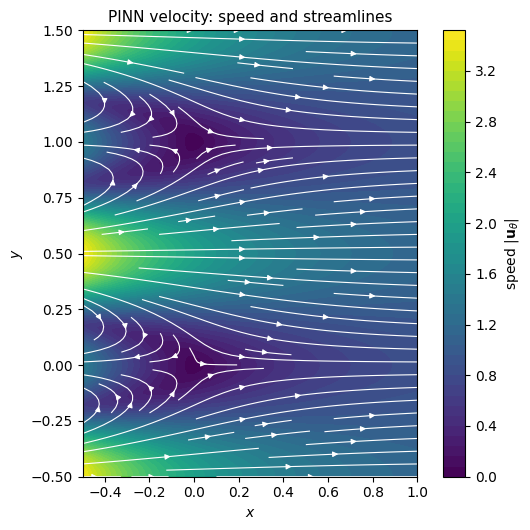

In [207]:
fig, ax = plt.subplots(figsize=(5.8, 5.4))
cf = ax.contourf(X, Y, np.sqrt(U_pinn**2 + V_pinn**2), levels=50, cmap="viridis")
ax.streamplot(xs, ys, U_pinn, V_pinn, color="white", density=1.2, linewidth=0.8, arrowsize=0.8)
fig.colorbar(cf, ax=ax, label=r"speed $|\mathbf{u}_\theta|$")
ax.set_xlabel("$x$"); ax.set_ylabel("$y$"); ax.set_aspect("equal")
ax.set_xlim(X_MIN, X_MAX); ax.set_ylim(Y_MIN, Y_MAX)
ax.set_title("PINN velocity: speed and streamlines")
plt.tight_layout()
plt.show()

## 3.8 Summary

- A **PINN** minimizes the PDE residual at collocation points plus boundary (and data) misfits; derivatives come from **automatic differentiation** (`torch.autograd.grad(..., create_graph=True)`).
- In the **incompressible Navier-Stokes equations** the pressure enforces $\nabla\cdot\mathbf{u} = 0$; with velocity prescribed on the whole boundary, its additive constant must be fixed.
- Smooth activations, input normalization and Adam followed by L-BFGS make training robust. On Kovasznay flow the PINN reached relative $L^2$ errors of about $10^{-3}$ or below.
- **Practical tips:** nondimensionalize the PDE and normalize the inputs to about $[-1, 1]$; balance the loss terms (a dominating term makes the others ignored); test the residual code with an exact solution and compare with a reference; and know the limits: high Reynolds numbers, thin layers and turbulence are hard for PINNs.

**PINN or FEM?** A comparison with the finite element method of Part 2:

| Aspect | PINN | Finite element method |
|:--|:--|:--|
| Discretization | mesh-free collocation points | mesh of the domain |
| Solver | non-convex optimization (Adam, L-BFGS) | (non)linear algebraic systems, fast solvers |
| Accuracy and speed (forward problems) | usually lower and slower | usually higher and faster |
| Error control | no practical guarantees | convergence theory, error estimators, adaptivity |
| Data and inverse problems | easy: data term, trainable coefficients | possible, needs adjoints or optimization loops |

# References

**Part 1: Introduction to Jupyter Notebook**

- F. Perez, B. E. Granger, "IPython: A System for Interactive Scientific Computing", *Computing in Science & Engineering* 9(3), 21-29, 2007.
- T. Kluyver et al., "Jupyter Notebooks - a publishing format for reproducible computational workflows", in *Positioning and Power in Academic Publishing: Players, Agents and Agendas*, IOS Press, 87-90, 2016.
- D. E. Knuth, "Literate Programming", *The Computer Journal* 27(2), 97-111, 1984.
- Project Jupyter documentation: https://docs.jupyter.org

**Part 2: Finite Elements for the 1D Heat Equation**

- V. Thomée, *Galerkin Finite Element Methods for Parabolic Problems*, 2nd ed., Springer, 2006.
- S. Larsson, V. Thomée, *Partial Differential Equations with Numerical Methods*, Springer, 2003.
- J. Crank, P. Nicolson, "A practical method for numerical evaluation of solutions of partial differential equations of the heat-conduction type", *Proceedings of the Cambridge Philosophical Society* 43(1), 50-67, 1947.
- S. C. Brenner, L. R. Scott, *The Mathematical Theory of Finite Element Methods*, 3rd ed., Springer, 2008.

**Part 3: Physics-Informed Neural Networks for the 2D Navier-Stokes Equations**

- I. E. Lagaris, A. Likas, D. I. Fotiadis, "Artificial neural networks for solving ordinary and partial differential equations", *IEEE Transactions on Neural Networks* 9(5), 987-1000, 1998.
- M. Raissi, P. Perdikaris, G. E. Karniadakis, "Physics-informed neural networks: A deep learning framework for solving forward and inverse problems involving nonlinear partial differential equations", *Journal of Computational Physics* 378, 686-707, 2019.
- G. E. Karniadakis, I. G. Kevrekidis, L. Lu, P. Perdikaris, S. Wang, L. Yang, "Physics-informed machine learning", *Nature Reviews Physics* 3, 422-440, 2021.
- L. I. G. Kovasznay, "Laminar flow behind a two-dimensional grid", *Mathematical Proceedings of the Cambridge Philosophical Society* 44(1), 58-62, 1948.
- X. Jin, S. Cai, H. Li, G. E. Karniadakis, "NSFnets (Navier-Stokes flow nets): Physics-informed neural networks for the incompressible Navier-Stokes equations", *Journal of Computational Physics* 426, 109951, 2021.
- D. P. Kingma, J. Ba, "Adam: A method for stochastic optimization", *International Conference on Learning Representations (ICLR)*, 2015.
- A. Paszke et al., "PyTorch: An imperative style, high-performance deep learning library", *Advances in Neural Information Processing Systems (NeurIPS)*, 2019.